# Healthcare & Pharma Data Analysis with Pandas
**Exploratory Data Analysis (EDA) of German hospital admissions, 2022-2025**

## Project Overview

### Introduction
This project is an end-to-end analysis of hospital admissions in German hospitals (2022-2025), built with Python and Pandas. Each row is one admission and holds patient details, department, ICD-10 diagnoses, prescribed medicine, vital signs, lab results, length of stay, charges, insurance, payment status and outcomes. The file has **48,000 rows and 30 columns**.

### Objective
Turn a raw healthcare file into a cleaned, validated and documented dataset, then answer practical questions about patients, departments, medicines, costs and outcomes. Every question below has **a graph** and a **conclusion that explains what we see and why it happened**.

### How each conclusion is written
- **What we see:** the numbers from the output.
- **Why it happened:** the reason behind the numbers (data generation, a rule in the code, or a real-world expectation that is missing).

## 1. Data Collection
| Item | Detail |
|---|---|
| Source file | `healthcare_pharma_1.csv` |
| Format | CSV |
| Rows x columns | 48,000 x 30 |
| Period | Admissions from 2022 to 2025 |
| Tools | Pandas, NumPy, Matplotlib, Seaborn |

The 30 columns fall into these groups:

| Data category | Example columns |
|---|---|
| Patient information | patient_id, patient_name, age, gender |
| Hospital information | city, department, attending_physician |
| Medical information | primary_diagnosis, secondary_diagnosis, medications_prescribed, blood_type |
| Clinical measurements | blood pressure, heart rate, temperature, glucose, hemoglobin |
| Admission details | admission_date, discharge_date, length_of_stay_days |
| Financial information | total_charges_eur, insurance_coverage_pct, insurance_provider, payment_status |
| Patient outcomes | readmission_30days, discharge_status, satisfaction_score |

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 4.5)
pd.set_option("display.max_columns", 40)

FILE_PATH = r"C:\Users\SIBIN\Downloads\healthcare_pharma_1.csv"   # change this if the file is somewhere else
df = pd.read_csv(FILE_PATH)
df.head()

,patient_id,mrn,patient_name,date_of_birth,age,gender,blood_type,city,insurance_provider,admission_date,discharge_date,department,primary_diagnosis,secondary_diagnosis,attending_physician,medications_prescribed,vital_signs_bp_systolic,vital_signs_bp_diastolic,vital_signs_heart_rate,vital_signs_temperature,lab_result_glucose,lab_result_hemoglobin,length_of_stay_days,readmission_30days,discharge_status,total_charges_eur,insurance_coverage_pct,payment_status,satisfaction_score,created_at
0,PAT-202300000,MRN-672723197,Petra Sowah,06-02-1931,85,Male,O-,Stuttgart,AOK,06-05-2023,16-04-2023,Surgery,E78,None,Dr. A. Mensah,Lisinopril 50mg,176,86,106,38.0,135.0,13.4,13,False,Rehab,44263.49,82.3,Pending,1,27-03-2023 15:50:00
1,PAT-202300001,MRN-196767697,Daniel Hoffmann,29-11-1980,79,Male,B+,Leipzig,Barmer,16-12-2025,08-08-2024,Surgery,M54,I10,Dr. A. Wolf,Lisinopril 20mg,171,106,87,38.8,196.3,16.7,49,True,Rehab,25716.57,73.2,Partial,3,28-01-2023 02:21:00
2,PAT-202300002,MRN-334977244,Anna Koch,02-11-1965,36,Male,AB+,Cologne,Self-pay,08-06-2024,10-11-2022,Dermatology,I10,None,Dr. W. Boateng,Aspirin 100mg,94,91,85,38.5,136.5,10.2,7,False,Transfer,8227.03,80.2,Denied,4,07-08-2023 21:01:00
3,PAT-202300003,MRN-977771770,Leon Richter,28-02-1976,69,Divers,Unknown,Bremen,Private,09-06-2024,22-09-2025,Emergency,M54,K57,Dr. F. Boateng,None Prescribed,139,82,60,38.0,93.3,14.0,3,False,Rehab,31334.15,95.4,Pending,3,19-11-2023 07:49:00
4,PAT-202300004,MRN-885711409,Christina Muller,22-04-2009,74,Female,O+,Nuremberg,AXA,22-11-2024,22-02-2023,Dermatology,E11,J18,Dr. A. Wagner,None Prescribed,146,85,85,37.3,82.2,12.6,15,True,Transfer,34109.32,81.5,Paid,3,18-11-2023 00:19:00


## 2. Data Cleaning
Checks done: shape, missing values, duplicate rows, text formatting, date conversion.

In [7]:
print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df.info()

Shape: (48000, 30)
Missing values: 0
Duplicate rows: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 30 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   patient_id                48000 non-null  object 
 1   mrn                       48000 non-null  object 
 2   patient_name              48000 non-null  object 
 3   date_of_birth             48000 non-null  object 
 4   age                       48000 non-null  int64  
 5   gender                    48000 non-null  object 
 6   blood_type                48000 non-null  object 
 7   city                      48000 non-null  object 
 8   insurance_provider        48000 non-null  object 
 9   admission_date            48000 non-null  object 
 10  discharge_date            48000 non-null  object 
 11  department                48000 non-null  object 
 12  primary_diagnosis         48000 non-null  object 
 13  second

In [8]:
# remove duplicates and extra spaces in text columns
df = df.drop_duplicates()

text_columns = ["gender", "city", "department", "primary_diagnosis", "secondary_diagnosis",
                "insurance_provider", "payment_status"]
for col in text_columns:
    df[col] = df[col].str.strip()

# convert the date columns once, so every question below can use them
for col in ["admission_date", "discharge_date", "created_at"]:
    df[col] = pd.to_datetime(df[col], dayfirst=True, errors="coerce")

# age groups used in several questions (ages run from 1 to 95)
df["age_group"] = pd.cut(df.age, [0, 17, 35, 50, 65, 80, 120],
                         labels=["0-17", "18-35", "36-50", "51-65", "66-80", "80+"])

print("Age range:", df.age.min(), "to", df.age.max())
print("Rows after cleaning:", len(df))

Age range: 1 to 95
Rows after cleaning: 48000


**Cleaning summary**

| Cleaning task | Result |
|---|---|
| Missing values | 0 NaN in every column, but some missing information is hidden inside text values (see Q1) |
| Duplicate rows | 0 exact duplicates |
| Text formatting | Spaces removed from the text columns |
| Dates | `admission_date`, `discharge_date`, `created_at` converted to datetime |
| Data quality | Impossible values and illogical combinations found in the questions below |

## Part A: Data quality and patient profile (Q1 to Q9)

### Q1. Is the data really clean? Check NaN, duplicate patients and hidden missing values.
A check with `isna()` only finds empty cells. Which 'missing' information is hidden inside normal-looking values?

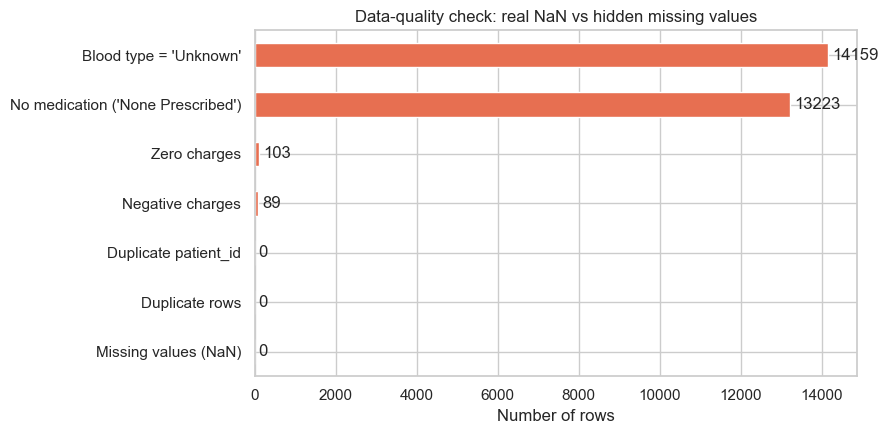

In [9]:
issues = pd.Series({
    "Missing values (NaN)": df.isna().sum().sum(),
    "Duplicate rows": df.duplicated().sum(),
    "Duplicate patient_id": df.patient_id.duplicated().sum(),
    "Blood type = 'Unknown'": (df.blood_type == "Unknown").sum(),
    "No medication ('None Prescribed')": (df.medications_prescribed == "None Prescribed").sum(),
    "Zero charges": (df.total_charges_eur == 0).sum(),
    "Negative charges": (df.total_charges_eur < 0).sum(),
}).astype(int).sort_values()

ax = issues.plot.barh(color=["#2a9d8f" if v == 0 else "#e76f51" for v in issues.values])
ax.bar_label(ax.containers[0], padding=3)
plt.title("Data-quality check: real NaN vs hidden missing values")
plt.xlabel("Number of rows"); plt.tight_layout(); plt.show()

**Conclusion**
- **What we see:** NaN, duplicate rows and duplicate `patient_id` are all 0. But 29.5% of blood types are 'Unknown', 27.5% of patients have 'None Prescribed', 103 bills have zero charges, and negative charges exist.
- **Why it happened:** `isna()` only counts empty cells. Here the missing information is written as normal text ('Unknown', 'None Prescribed') or was filled earlier (for example satisfaction scores filled with the median), so the data looks clean but is not. `patient_id` has no duplicates because each ID was created once per row.

### Q2. Which categories does each text column contain, and how many are there?
How many unique values does each text column have, and are there spelling variants left?

,unique,sample values
date_of_birth,26242,"[01-01-1930, 01-01-1931, 01-01-1932, 01-01-193..."
gender,3,"[Divers, Female, Male]"
blood_type,9,"[A+, A-, AB+, AB-, B+, B-]"
city,15,"[Berlin, Bremen, Cologne, Dortmund, Dresden, D..."
insurance_provider,8,"[AOK, AXA, Allianz, Barmer, DAK, Private]"
department,10,"[Cardiology, Dermatology, Emergency, Internal ..."
primary_diagnosis,12,"[E11, E78, F32, G43, I10, I25]"
secondary_diagnosis,13,"[E11, E78, F32, G43, I10, I25]"
attending_physician,120,"[Dr. A. Agyeman, Dr. A. Bauer, Dr. A. Becker, ..."
medications_prescribed,25,"[Amlodipine 100mg, Amlodipine 10mg, Amlodipine..."


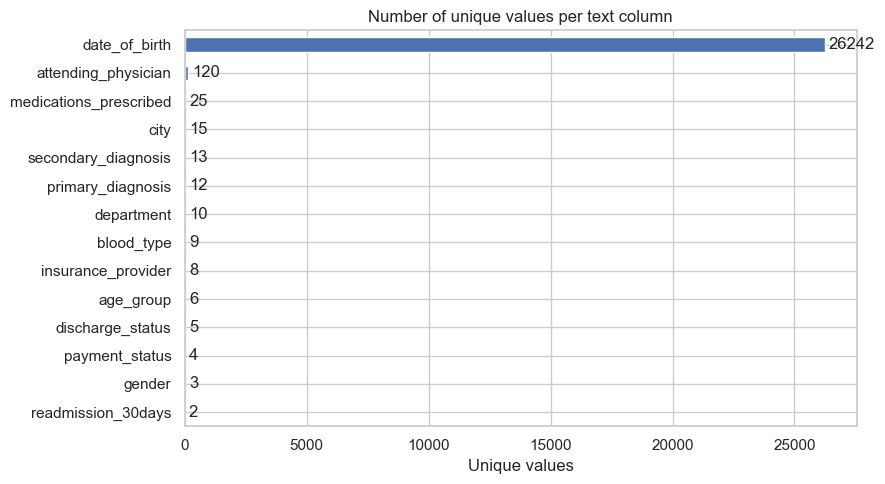

In [10]:
cat_cols = df.select_dtypes(exclude=["number", "datetime"]).columns.drop(["patient_id", "mrn", "patient_name"])
summary = pd.DataFrame({"unique": df[cat_cols].nunique(),
                        "sample values": [sorted(df[c].dropna().unique())[:6] for c in cat_cols]})
display(summary)

ax = summary["unique"].sort_values().plot.barh(figsize=(9, 5))
ax.bar_label(ax.containers[0], padding=3)
plt.title("Number of unique values per text column"); plt.xlabel("Unique values")
plt.tight_layout(); plt.show()

**Conclusion**
- **What we see:** Gender has 3 values, and there are 10 departments, 12 primary diagnoses, 8 insurers, 15 cities and 120 physicians. No spelling variants are left.
- **Why it happened:** `str.strip()` merged values such as "Berlin " and "Berlin", and the values come from fixed lists, so the categories are few and consistent. Physicians have 120 values because each one is a name or ID, not a real category, so it is useful for `groupby` but not for a simple chart.

### Q3. Are adult-age patients admitted to Pediatrics (and do all departments share the same ages)?
A real Pediatrics department treats children only. How many Pediatrics patients are 18 or older?

Pediatrics patients aged 18+: 3989 of 4851 (82%)


,min,median,max
department,,,
Cardiology,1,47.0,95
Dermatology,1,47.0,95
Emergency,1,48.0,95
Internal Medicine,1,48.0,95
Neurology,1,48.0,95
Oncology,1,47.0,95
Orthopedics,1,48.0,95
Pediatrics,1,49.0,95
Radiology,1,47.0,95


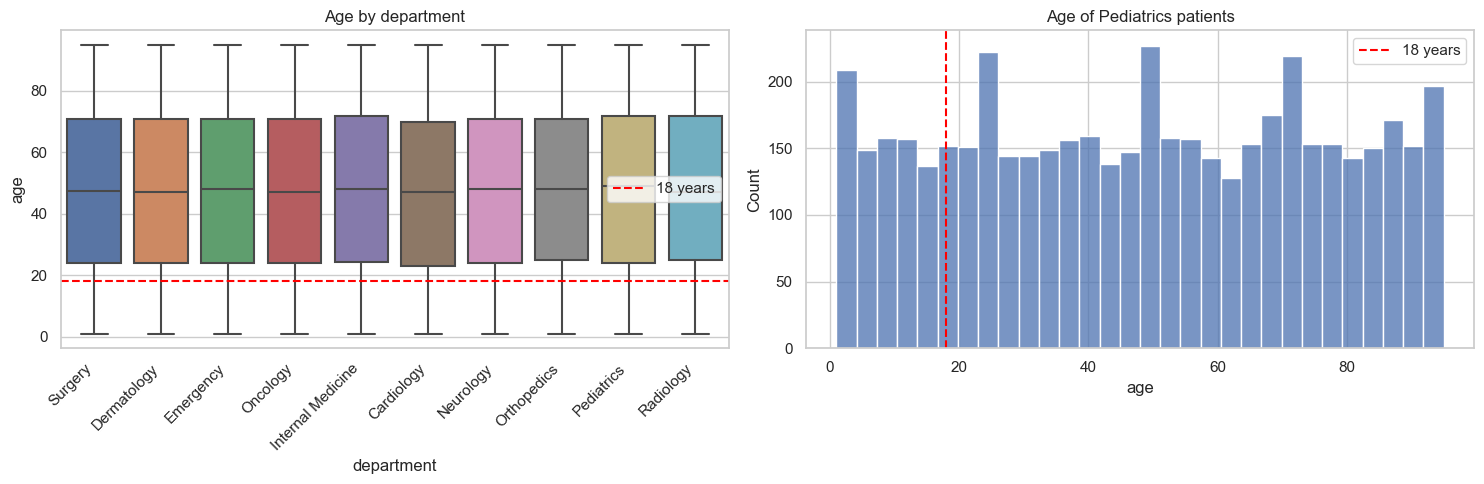

In [11]:
ped = df.department == "Pediatrics"
adults_in_ped = (ped & (df.age >= 18)).sum()
print(f"Pediatrics patients aged 18+: {adults_in_ped} of {ped.sum()} ({adults_in_ped / ped.sum():.0%})")
display(df.groupby("department").age.agg(["min", "median", "max"]))

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=df, x="department", y="age", ax=ax[0])
ax[0].axhline(18, color="red", ls="--", label="18 years")
ax[0].set_title("Age by department"); ax[0].legend()
plt.setp(ax[0].get_xticklabels(), rotation=45, ha="right")
sns.histplot(df[ped].age, bins=30, ax=ax[1])
ax[1].axvline(18, color="red", ls="--", label="18 years")
ax[1].set_title("Age of Pediatrics patients"); ax[1].legend()
plt.tight_layout(); plt.show()

**Conclusion**
- **What we see:** 3,989 of 4,851 Pediatrics patients (82%) are 18 or older, and every department has ages from 1 to 95.
- **Why it happened:** The department was assigned at random, independent of age. If ages are spread evenly from 1 to 95, then 78 of the 95 ages (82%) are 18 or older, which is exactly the share we see in Pediatrics. In a real hospital the department decides who is admitted, so Pediatrics would have almost no adults.

### Q4. Are there zero-charge bills, or logical conflicts between insurance, coverage and payment status?
Count bills with zero charges, 100% coverage but 'Denied' payment, and 'Self-pay' patients with insurance coverage.

Negative charges                      89
Zero charges                         103
100% coverage but payment Denied    1751
Self-pay with coverage > 0%         5974
dtype: int32
Self-pay patients in total: 5974


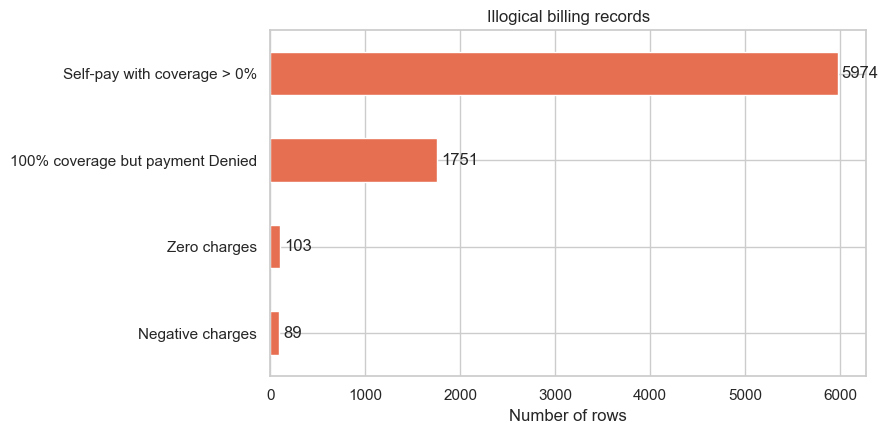

In [12]:
self_pay = df.insurance_provider == "Self-pay"
checks = pd.Series({
    "Zero charges": (df.total_charges_eur == 0).sum(),
    "Negative charges": (df.total_charges_eur < 0).sum(),
    "100% coverage but payment Denied": ((df.insurance_coverage_pct == 100) & (df.payment_status == "Denied")).sum(),
    "Self-pay with coverage > 0%": (self_pay & (df.insurance_coverage_pct > 0)).sum(),
}).astype(int).sort_values()
print(checks)
print(f"Self-pay patients in total: {self_pay.sum()}")

ax = checks.plot.barh(color="#e76f51")
ax.bar_label(ax.containers[0], padding=3)
plt.title("Illogical billing records"); plt.xlabel("Number of rows")
plt.tight_layout(); plt.show()

**Conclusion**
- **What we see:** 103 bills have zero charges, 1,751 patients have 100% coverage but a 'Denied' payment, and 5,974 Self-pay patients have insurance coverage above zero.
- **Why it happened:** `total_charges_eur`, `insurance_coverage_pct`, `insurance_provider` and `payment_status` were generated separately, with no business rule that connects them. A real system would force 'Self-pay' to 0% coverage and would not deny a bill that is fully covered.

### Q5. What is the age distribution, and which age group is the largest?
Is the patient population skewed towards older ages, like a real hospital?

0-17     8602
18-35    9263
36-50    7572
51-65    7631
66-80    7509
80+      7423
Name: age_group, dtype: int64


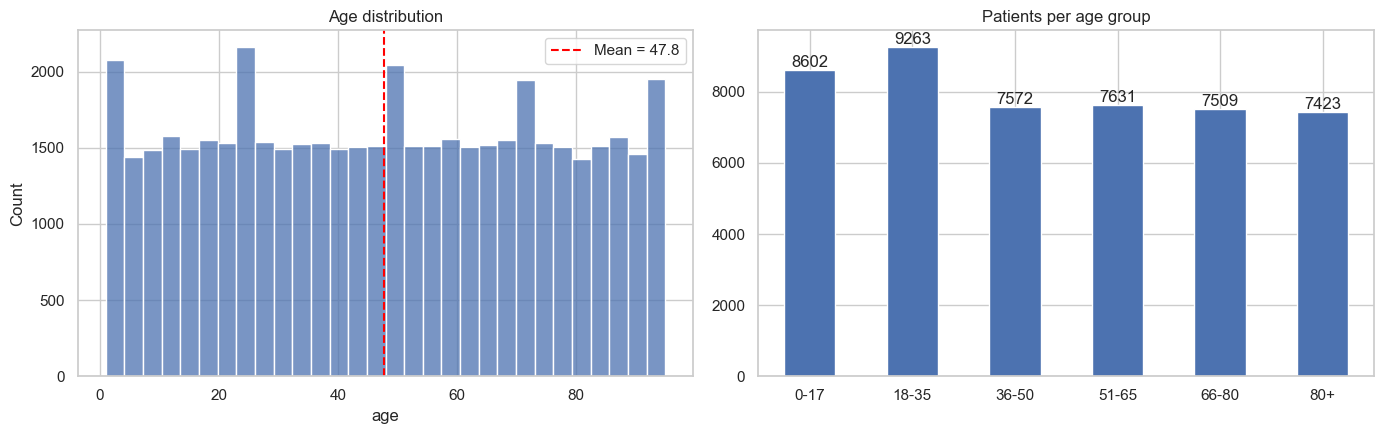

In [13]:
print(df.age_group.value_counts().sort_index())

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(df.age, bins=30, ax=ax[0])
ax[0].axvline(df.age.mean(), color="red", ls="--", label=f"Mean = {df.age.mean():.1f}")
ax[0].set_title("Age distribution"); ax[0].legend()
counts = df.age_group.value_counts().sort_index()
counts.plot.bar(ax=ax[1], rot=0, title="Patients per age group")
ax[1].bar_label(ax[1].containers[0])
plt.tight_layout(); plt.show()

**Conclusion**
- **What we see:** The histogram is flat. The 18-35 group is the largest (9,263), then 0-17 (8,602), and the other groups have about 7,400 to 7,600 each.
- **Why it happened:** Ages were drawn evenly between 1 and 95, so a group is bigger only because its age band is wider (18 years for 18-35, 17 for 0-17, 15 for the rest). A real hospital would show more elderly patients, so the histogram would lean to the right.

### Q6. How many male, female and divers patients are there?
What is the gender split, and is it realistic?

Female    40.0
Male      39.8
Divers    20.2
Name: gender, dtype: float64


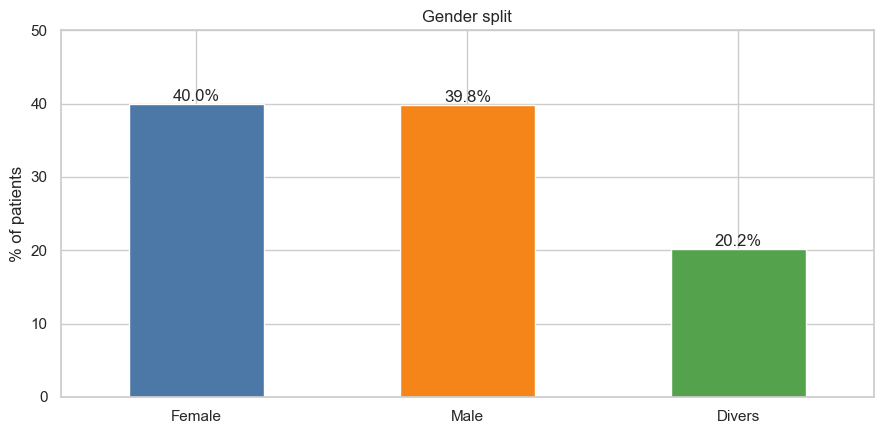

In [14]:
share = df.gender.value_counts(normalize=True) * 100
print(share.round(1))

ax = share.plot.bar(rot=0, color=["#4c78a8", "#f58518", "#54a24b"])
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.title("Gender split"); plt.ylabel("% of patients"); plt.ylim(0, 50)
plt.tight_layout(); plt.show()

**Conclusion**
- **What we see:** 40% Female, 39.8% Male and 20.2% Divers.
- **Why it happened:** Gender was most likely drawn with fixed probabilities (about 40/40/20). A 20% Divers share is much higher than in real populations, which is one more sign that this is generated data.

### Q7. Which cities and insurance providers have the most patients?
Is any city or insurer much bigger than the others? The red line shows the equal share.

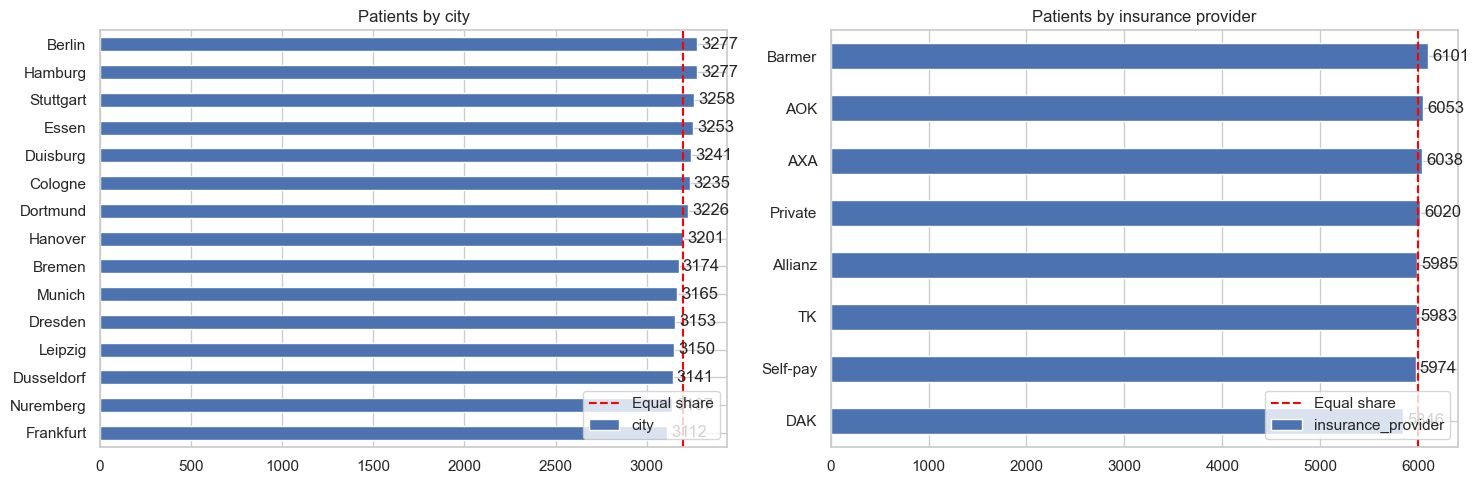

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for a, col, title in zip(ax, ["city", "insurance_provider"],
                         ["Patients by city", "Patients by insurance provider"]):
    c = df[col].value_counts().sort_values()
    c.plot.barh(ax=a, title=title)
    a.bar_label(a.containers[0], padding=3)
    a.axvline(len(df) / c.size, color="red", ls="--", label="Equal share")
    a.legend(loc="lower right")
plt.tight_layout(); plt.show()

**Conclusion**
- **What we see:** Hamburg and Berlin have the most patients (3,277 each) and Frankfurt the fewest (3,112). Barmer has the most (6,101) and DAK the fewest (5,846) among insurers.
- **Why it happened:** If 48,000 patients are shared equally, each of the 15 cities gets 3,200 and each of the 8 insurers gets 6,000. All bars sit within about 3% of the red line, so the gaps are only random noise. Patients were assigned to cities and insurers with equal chance, not by real population size or market share.

### Q8. What are the most common primary and secondary diagnoses and the most prescribed medicines?
Which diagnoses and drugs dominate? (The drug name is taken from the text, e.g. 'Aspirin 100mg' becomes 'Aspirin'.)

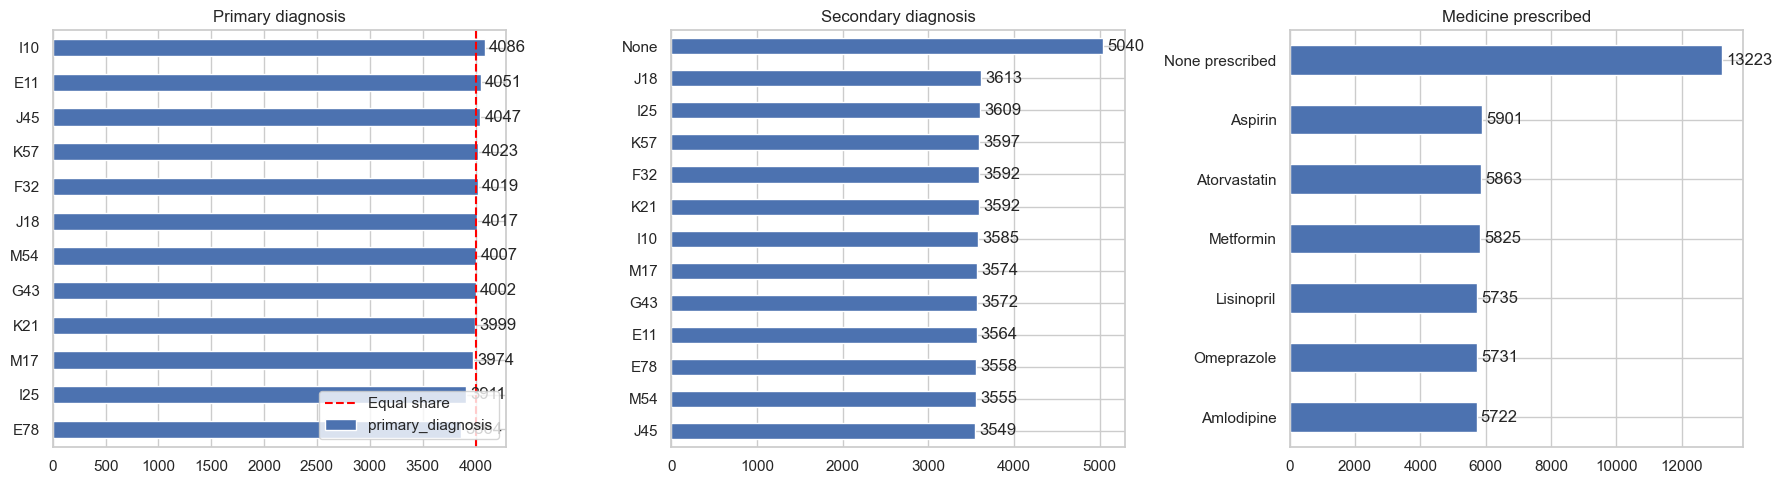

None    5040
J18     3613
I25     3609
Name: secondary_diagnosis, dtype: int64
None prescribed    13223
Aspirin             5901
Atorvastatin        5863
Metformin           5825
Lisinopril          5735
Omeprazole          5731
Amlodipine          5722
Name: medications_prescribed, dtype: int64


In [16]:
drug = (df.medications_prescribed.str.extract(r"^([A-Za-z]+) \d+mg$", expand=False)
          .fillna("None prescribed"))

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
primary = df.primary_diagnosis.value_counts().sort_values()
primary.plot.barh(ax=ax[0], title="Primary diagnosis")
ax[0].axvline(len(df) / primary.size, color="red", ls="--", label="Equal share")
ax[0].legend(loc="lower right")
df.secondary_diagnosis.value_counts().sort_values().plot.barh(ax=ax[1], title="Secondary diagnosis")
drug.value_counts().sort_values().plot.barh(ax=ax[2], title="Medicine prescribed")
for a in ax:
    a.bar_label(a.containers[0], padding=3)
plt.tight_layout(); plt.show()

print(df.secondary_diagnosis.value_counts().head(3))
print(drug.value_counts())

**Conclusion**
- **What we see:** The top primary diagnoses are I10 (4,086), E11 (4,051) and J45 (4,047), but all 12 are close to 4,000. 5,040 patients have no secondary diagnosis and 13,223 have no medication. Aspirin (5,901), Atorvastatin (5,863) and Metformin (5,825) lead, and all six drugs are used almost equally.
- **Why it happened:** 48,000 / 12 diagnoses = 4,000 each, so diagnoses were assigned with equal chance. In real hospitals hypertension and diabetes are far more common than rare diseases. Drugs were also picked at random from a list of six, so prescriptions do not follow the diagnoses.

### Q9. What share of patients have an unknown blood type, and how are the known types distributed?
How much blood-type information is missing, and does the known distribution look real?

Unknown blood type: 29.5%
O+     12.2
A-     12.3
O-     12.4
A+     12.4
B-     12.6
B+     12.6
AB-    12.7
AB+    12.8
Name: blood_type, dtype: float64


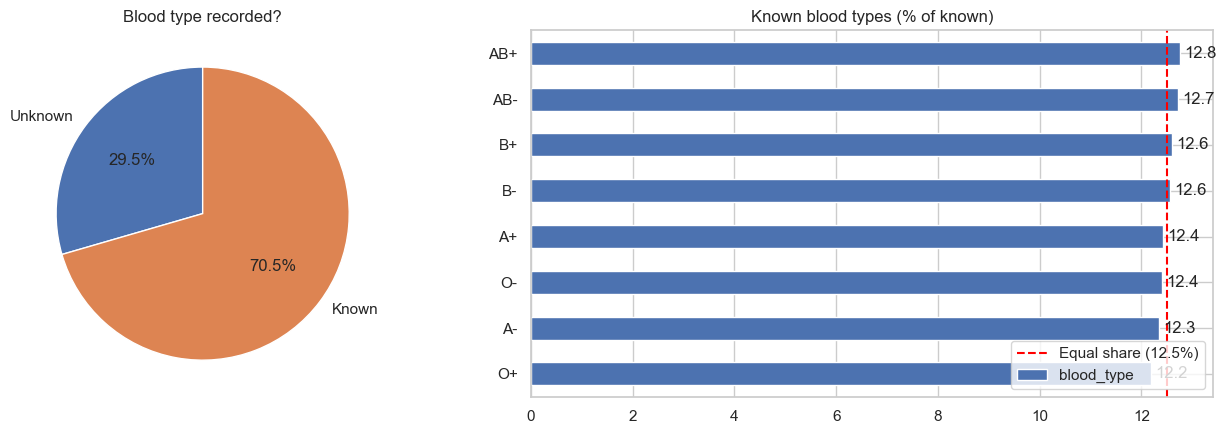

In [17]:
unknown = (df.blood_type == "Unknown").mean()
known = df[df.blood_type != "Unknown"].blood_type.value_counts(normalize=True).sort_values() * 100
print(f"Unknown blood type: {unknown:.1%}")
print(known.round(1))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].pie([unknown, 1 - unknown], labels=["Unknown", "Known"], autopct="%1.1f%%", startangle=90)
ax[0].set_title("Blood type recorded?")
known.plot.barh(ax=ax[1], title="Known blood types (% of known)")
ax[1].axvline(100 / len(known), color="red", ls="--", label="Equal share (12.5%)")
ax[1].bar_label(ax[1].containers[0], fmt="%.1f", padding=3); ax[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

**Conclusion**
- **What we see:** 29.5% of patients have an unknown blood type. Among the known types all eight are almost equal (12.2% to 12.8%).
- **Why it happened:** Blood type was picked with equal chance from 8 types (100 / 8 = 12.5% each), and 'Unknown' acts as a hidden missing value. In real populations O+ and A+ are far more common and AB- is rare, so the bars would be very uneven.

## Part B: Length of stay, vitals and lab results (Q10 to Q14)

### Q10. Calculate the average and median length of stay for each department and rank them.
Which department has the longest stays, and are the differences real?

,mean,median,rank
department,,,
Neurology,30.61,31.0,1
Internal Medicine,30.33,30.0,2
Pediatrics,30.15,30.0,3
Cardiology,29.93,30.0,4
Orthopedics,29.92,30.0,5
Oncology,29.78,30.0,6
Radiology,29.71,29.0,7
Surgery,29.68,29.0,8
Dermatology,29.64,30.0,9


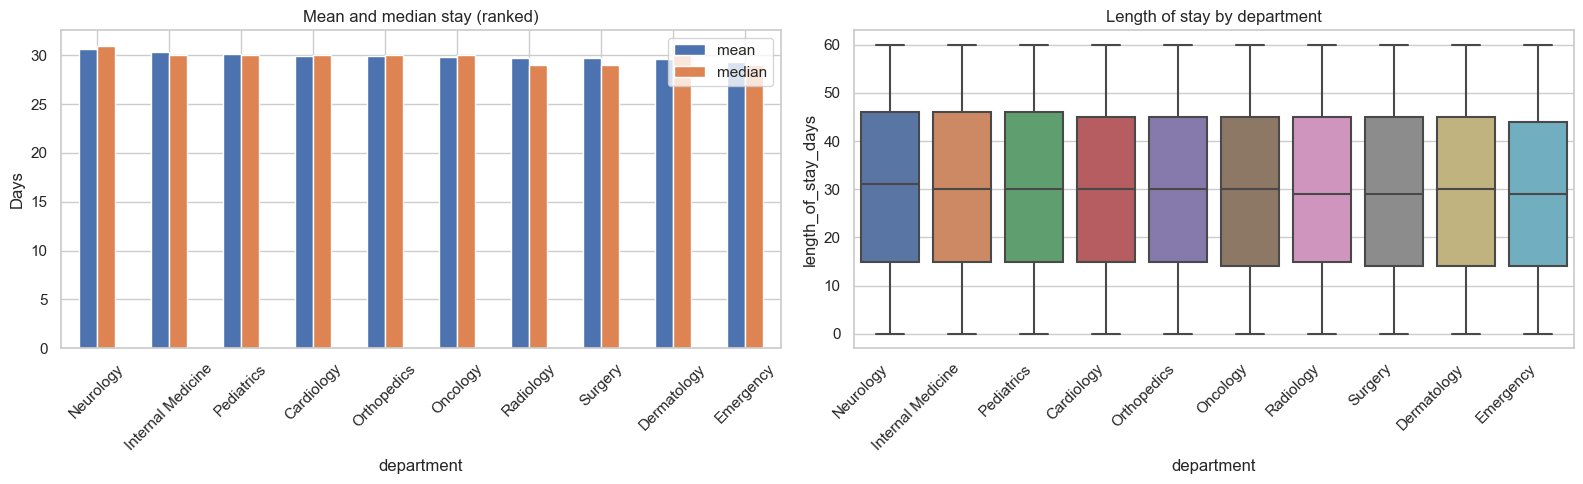

In [18]:
los = (df.groupby("department").length_of_stay_days.agg(mean="mean", median="median")
         .round(2).sort_values("mean", ascending=False))
los["rank"] = range(1, len(los) + 1)
display(los)

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
los[["mean", "median"]].plot.bar(ax=ax[0], rot=45)
ax[0].set_title("Mean and median stay (ranked)"); ax[0].set_ylabel("Days")
sns.boxplot(data=df, x="department", y="length_of_stay_days", order=los.index, ax=ax[1])
ax[1].set_title("Length of stay by department")
plt.setp(ax[1].get_xticklabels(), rotation=45, ha="right")
plt.tight_layout(); plt.show()

**Conclusion**
- **What we see:** The ranking table shows only small gaps, and the box plots look almost the same for every department (stays from 0 to 60 days).
- **Why it happened:** Length of stay was drawn from the same 0-60 day range for every department, so the ranking is only random noise. In a real hospital surgery and intensive care would stay much longer than radiology or emergency.

### Q11. What share of patients have hypertension-range blood pressure (>= 140/90), and is it higher for diagnosis I10?
Do hypertension (I10) patients really have higher blood pressure than other patients?

Overall high BP: 67.7%
primary_diagnosis
All other diagnoses    67.6
I10 (hypertension)     68.7
Name: high_bp, dtype: float64


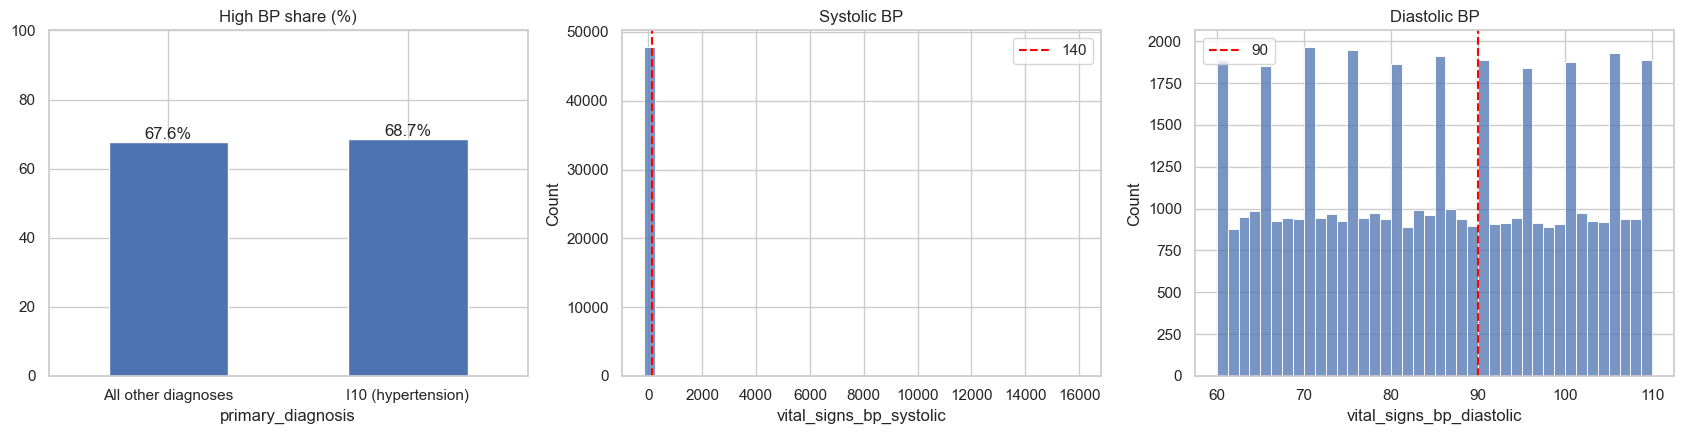

In [19]:
df["high_bp"] = (df.vital_signs_bp_systolic >= 140) | (df.vital_signs_bp_diastolic >= 90)
is_i10 = df.primary_diagnosis == "I10"
share = (df.groupby(is_i10).high_bp.mean() * 100).rename({True: "I10 (hypertension)", False: "All other diagnoses"})
print(f"Overall high BP: {df.high_bp.mean():.1%}")
print(share.round(1))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
share.plot.bar(ax=ax[0], rot=0, title="High BP share (%)")
ax[0].bar_label(ax[0].containers[0], fmt="%.1f%%"); ax[0].set_ylim(0, 100)
sns.histplot(df.vital_signs_bp_systolic, bins=40, ax=ax[1])
ax[1].axvline(140, color="red", ls="--", label="140"); ax[1].set_title("Systolic BP"); ax[1].legend()
sns.histplot(df.vital_signs_bp_diastolic, bins=40, ax=ax[2])
ax[2].axvline(90, color="red", ls="--", label="90"); ax[2].set_title("Diastolic BP"); ax[2].legend()
plt.tight_layout(); plt.show()

**Conclusion**
- **What we see:** 67.7% of patients have high blood pressure: 68.7% for I10 and 67.6% for all others.
- **Why it happened:** The rule marks a patient as high if systolic >= 140 **or** diastolic >= 90, so one high number is enough, and with these blood pressure values most patients cross at least one line. Blood pressure was also generated independently of the diagnosis, so I10 patients are not higher. In real data hypertension patients show clearly higher readings.

### Q12. Do diabetic patients (E11) have higher glucose than others?
Is the glucose level linked to the diabetes diagnosis?

                    mean  median  count
primary_diagnosis                      
False              135.0   135.0  43949
True               135.2   135.0   4051


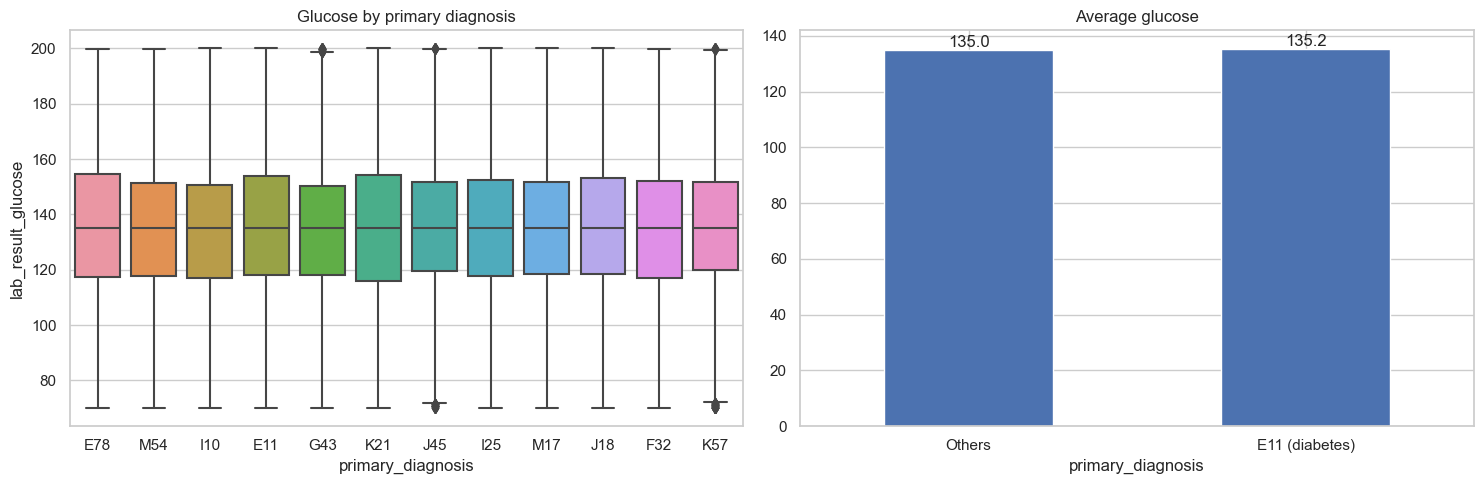

In [20]:
is_e11 = df.primary_diagnosis == "E11"
print(df.groupby(is_e11).lab_result_glucose.agg(["mean", "median", "count"]).round(1))

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=df, x="primary_diagnosis", y="lab_result_glucose", ax=ax[0])
ax[0].set_title("Glucose by primary diagnosis")
df.groupby(is_e11).lab_result_glucose.mean().rename({True: "E11 (diabetes)", False: "Others"}).plot.bar(
    ax=ax[1], rot=0, title="Average glucose")
ax[1].bar_label(ax[1].containers[0], fmt="%.1f")
plt.tight_layout(); plt.show()

**Conclusion**
- **What we see:** E11 patients have an average glucose of 135.2 versus 135.0 for everyone else.
- **Why it happened:** Glucose was generated from the same random range for all 12 diagnoses, with no link to the disease. In real data diabetic patients usually have clearly higher glucose.

### Q13. What share of patients have fever (>= 38 C) or tachycardia (heart rate > 100)?
Is the share of abnormal vital signs realistic for a normal patient group?

Fever (>= 38 C)           44.6
Tachycardia (HR > 100)    28.5
dtype: float64


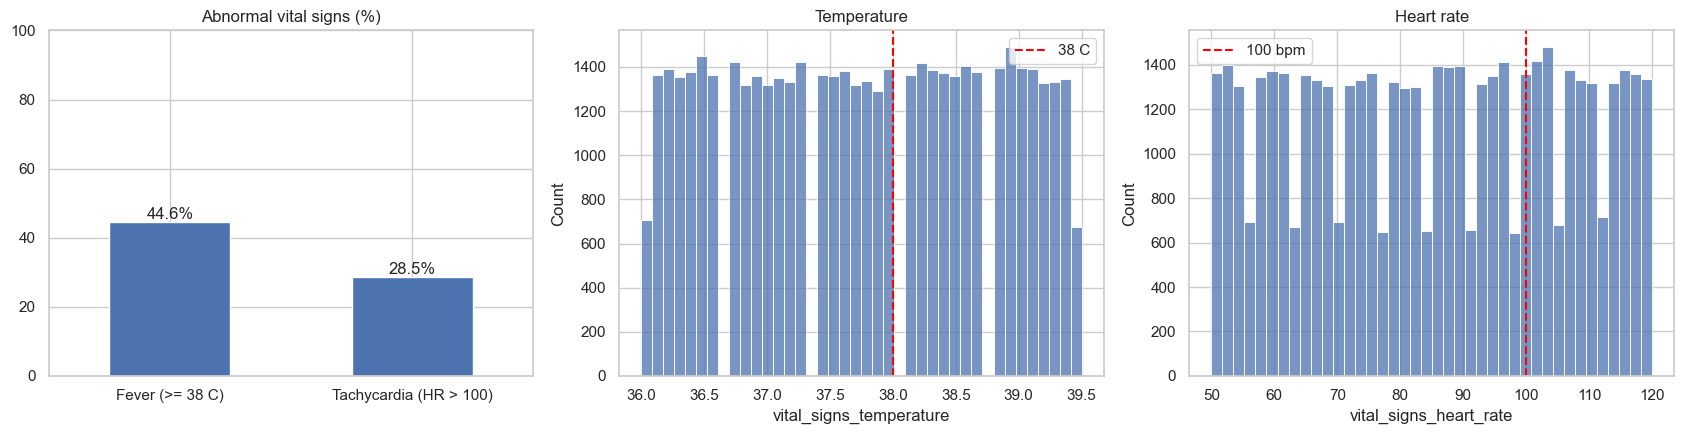

In [21]:
fever = df.vital_signs_temperature >= 38
tachy = df.vital_signs_heart_rate > 100
rates = pd.Series({"Fever (>= 38 C)": fever.mean() * 100, "Tachycardia (HR > 100)": tachy.mean() * 100})
print(rates.round(1))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
rates.plot.bar(ax=ax[0], rot=0, title="Abnormal vital signs (%)")
ax[0].bar_label(ax[0].containers[0], fmt="%.1f%%"); ax[0].set_ylim(0, 100)
sns.histplot(df.vital_signs_temperature, bins=40, ax=ax[1])
ax[1].axvline(38, color="red", ls="--", label="38 C"); ax[1].set_title("Temperature"); ax[1].legend()
sns.histplot(df.vital_signs_heart_rate, bins=40, ax=ax[2])
ax[2].axvline(100, color="red", ls="--", label="100 bpm"); ax[2].set_title("Heart rate"); ax[2].legend()
plt.tight_layout(); plt.show()

**Conclusion**
- **What we see:** 44.6% of patients have a fever and 28.5% have a heart rate above 100.
- **Why it happened:** The values were generated over a wide range that is not centred on healthy values, so a large part of the data lands beyond the thresholds. In a real patient group only a minority has fever or tachycardia, and these signs would be linked to the diagnosis.

### Q14. Is anaemia (hemoglobin < 12 for females, < 13 for males) more common in any gender or age group?
Does anaemia differ by gender or age? (Divers uses 12.5 as an assumed cut-off.)

gender
Divers    20.5
Female    16.7
Male      24.9
Name: anaemia, dtype: float64
age_group
0-17     20.5
18-35    20.6
36-50    20.9
51-65    21.7
66-80    20.2
80+      20.3
Name: anaemia, dtype: float64


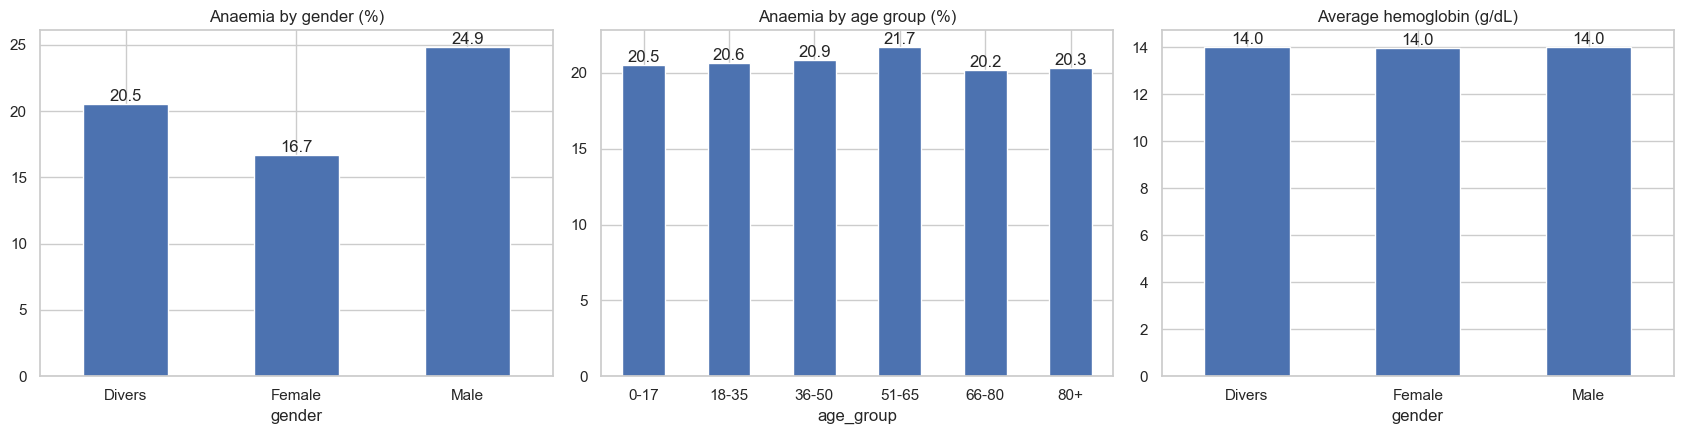

In [23]:
thr = df.gender.map({"Female": 12, "Male": 13, "Divers": 12.5})
df["anaemia"] = df.lab_result_hemoglobin < thr
by_gender = df.groupby("gender").anaemia.mean() * 100
by_age = df.groupby("age_group", observed=True).anaemia.mean() * 100
print(by_gender.round(1)); print(by_age.round(1))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
by_gender.plot.bar(ax=ax[0], rot=0, title="Anaemia by gender (%)")
by_age.plot.bar(ax=ax[1], rot=0, title="Anaemia by age group (%)")
df.groupby("gender").lab_result_hemoglobin.mean().plot.bar(ax=ax[2], rot=0, title="Average hemoglobin (g/dL)")
for a in ax:
    a.bar_label(a.containers[0], fmt="%.1f")
plt.tight_layout(); plt.show()

**Conclusion**
- **What we see:** Anaemia is 24.9% for males, 16.7% for females and 20.5% for Divers, but almost the same across age groups (about 20% to 22%).
- **Why it happened:** The gender gap comes from the different cut-offs (13 vs 12 vs 12.5 g/dL) applied to the same kind of hemoglobin values, not from a real difference between the groups (see the right chart). Hemoglobin does not change with age here, so the age groups are equal.

## Part C: Medication (Q15 to Q16)

### Q15. Which medicines are prescribed per primary diagnosis? (top drug for each)
Does each diagnosis get a sensible medicine, e.g. diabetes (E11) with Metformin?

primary_diagnosis
E11        Aspirin 100mg
E78    Atorvastatin 50mg
F32         Aspirin 50mg
G43     Omeprazole 100mg
I10         Aspirin 20mg
I25      Lisinopril 20mg
J18    Atorvastatin 20mg
J45      Amlodipine 10mg
K21    Atorvastatin 20mg
K57      Lisinopril 20mg
M17       Metformin 20mg
M54       Metformin 50mg
Name: most frequent, dtype: object

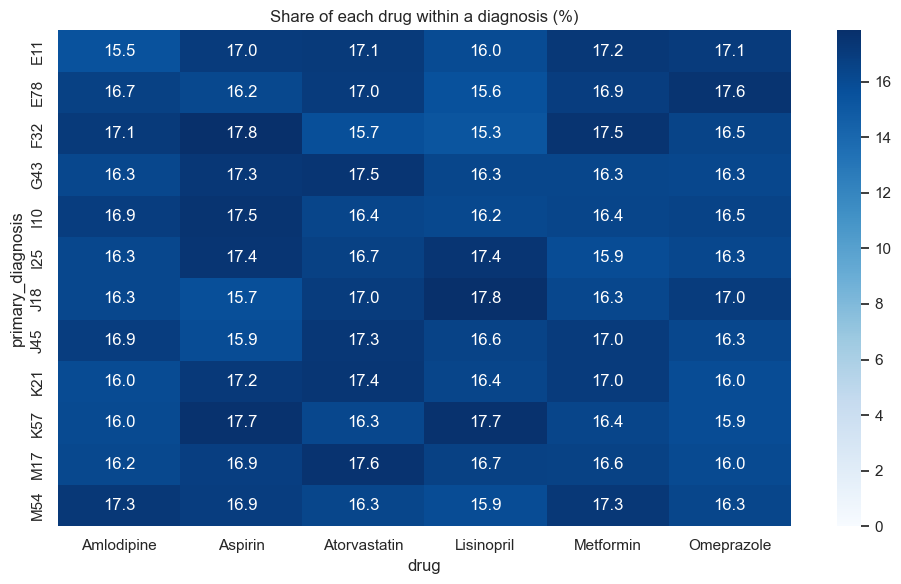

In [24]:
t = df[df.medications_prescribed != "None Prescribed"].copy()
t["drug"] = t.medications_prescribed.str.extract(r"^([A-Za-z]+) \d+mg$", expand=False)
display(t.groupby("primary_diagnosis").medications_prescribed.agg(lambda s: s.value_counts().idxmax()).rename("most frequent"))

ct = pd.crosstab(t.primary_diagnosis, t.drug, normalize="index") * 100
plt.figure(figsize=(10, 6))
sns.heatmap(ct, annot=True, fmt=".1f", cmap="Blues", vmin=0)
plt.title("Share of each drug within a diagnosis (%)")
plt.tight_layout(); plt.show()

**Conclusion**
- **What we see:** Each diagnosis has a different most frequent drug (for example E11 with Aspirin 100mg and M17 with Metformin 20mg), but every cell in the heatmap is close to the same value.
- **Why it happened:** Each patient got one of six drugs at random (about 16.7% each), so the 'top drug' is just the one that got a few more cases by chance. The pairs make little medical sense, because a diabetes diagnosis would normally lead to Metformin.

### Q16. How many patients have no medication prescribed, and is it related to the department?
Does the share of 'None Prescribed' change from department to department?

27.5% of patients have no medication


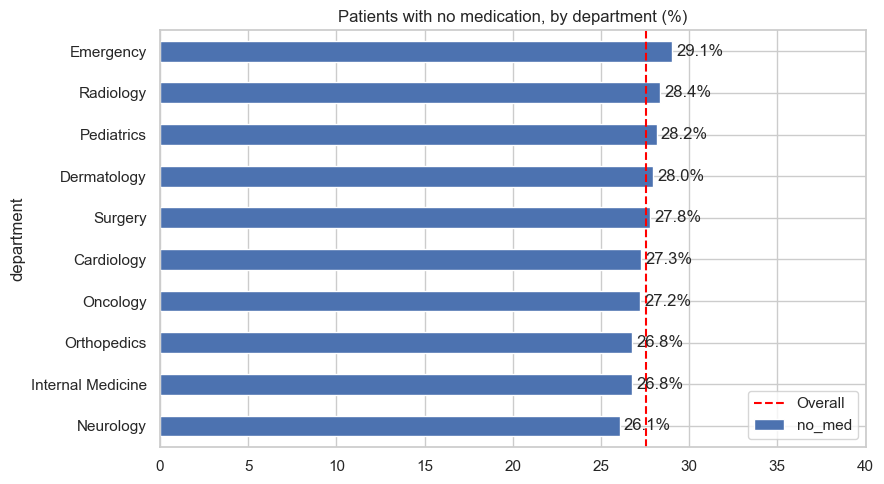

In [25]:
df["no_med"] = df.medications_prescribed == "None Prescribed"
by_dept = df.groupby("department").no_med.mean().sort_values() * 100
print(f"{df.no_med.mean():.1%} of patients have no medication")

ax = by_dept.plot.barh(figsize=(9, 5))
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.axvline(df.no_med.mean() * 100, color="red", ls="--", label="Overall")
ax.set_xlim(0, 40); ax.legend(loc="lower right")
plt.title("Patients with no medication, by department (%)")
plt.tight_layout(); plt.show()

**Conclusion**
- **What we see:** 27.5% of patients have no medication, from 26.1% in Neurology to 29.1% in Emergency.
- **Why it happened:** 'None Prescribed' is just one more random value of the medication column. With about 4,800 patients per department, a gap of 2-3 points is what chance alone produces, so the department has no real effect.

## Part D: Billing and revenue (Q17 to Q19)

### Q17. What is the total and average billing, and which insurer generates the most revenue?
Which insurer earns the most, and are the totals reliable (negative and extreme bills)?

Total charges: EUR 1,368,507,909 | Average: EUR 28,511
Negative bills: 89 | Largest bill: 4,381,635
Cleaned total (removed negative and bills above EUR 112,763): EUR 1,205,470,608


,sum,mean,count
insurance_provider,,,
Allianz,178487417.0,29822.0,5985
TK,175627323.0,29354.0,5983
AOK,175519183.0,28997.0,6053
AXA,173835888.0,28790.0,6038
Private,169473780.0,28152.0,6020
DAK,166525475.0,28485.0,5846
Self-pay,165799896.0,27754.0,5974
Barmer,163238947.0,26756.0,6101


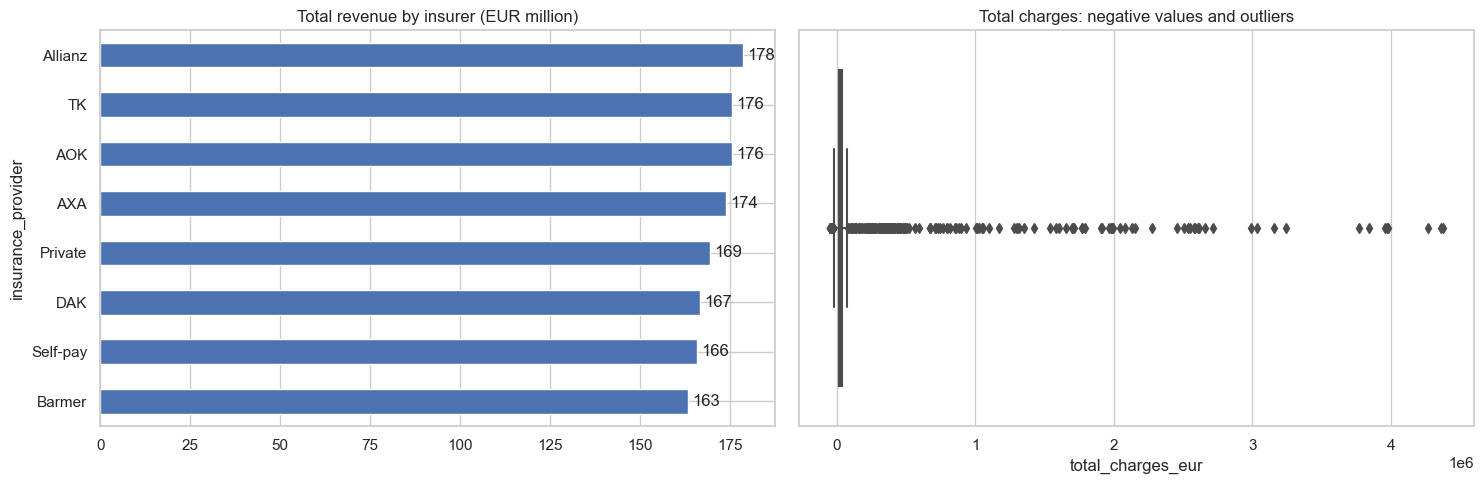

In [26]:
print(f"Total charges: EUR {df.total_charges_eur.sum():,.0f} | Average: EUR {df.total_charges_eur.mean():,.0f}")
print("Negative bills:", (df.total_charges_eur < 0).sum(), "| Largest bill:", f"{df.total_charges_eur.max():,.0f}")

# cleaned version: remove negative bills and extreme outliers (IQR rule)
q1, q3 = df.total_charges_eur.quantile([0.25, 0.75])
upper = q3 + 3 * (q3 - q1)
clean = df[(df.total_charges_eur > 0) & (df.total_charges_eur <= upper)]
print(f"Cleaned total (removed negative and bills above EUR {upper:,.0f}): EUR {clean.total_charges_eur.sum():,.0f}")

rev = df.groupby("insurance_provider").total_charges_eur.agg(["sum", "mean", "count"]).round(0).sort_values("sum", ascending=False)
display(rev)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
(rev["sum"] / 1e6).sort_values().plot.barh(ax=ax[0], title="Total revenue by insurer (EUR million)")
ax[0].bar_label(ax[0].containers[0], fmt="%.0f", padding=3)
sns.boxplot(x=df.total_charges_eur, ax=ax[1]); ax[1].set_title("Total charges: negative values and outliers")
plt.tight_layout(); plt.show()

**Conclusion**
- **What we see:** Total billing is about EUR 1.37 billion with an average of EUR 28,511 per patient, and Allianz brings the most revenue (about EUR 178 million). The total includes impossible values (negative charges and bills up to EUR 4.4 million); after removing them the total is clearly lower (about EUR 1.21 billion in the earlier check, and the cleaned total printed above).
- **Why it happened:** Barmer has the most patients but Allianz the most revenue, so Allianz's lead probably comes from a few very large bills and not from more patients. The extreme and negative values show that the charges were generated over a very wide range with no validation rule, so totals must be cleaned before they are reported.

### Q18. Does the cost per day differ between departments?
Are some departments more expensive per day (e.g. surgery vs radiology)?

department
Radiology            841.0
Dermatology          839.0
Cardiology           837.0
Emergency            836.0
Internal Medicine    836.0
Pediatrics           836.0
Surgery              833.0
Oncology             829.0
Orthopedics          826.0
Neurology            817.0
Name: cost_per_day, dtype: float64


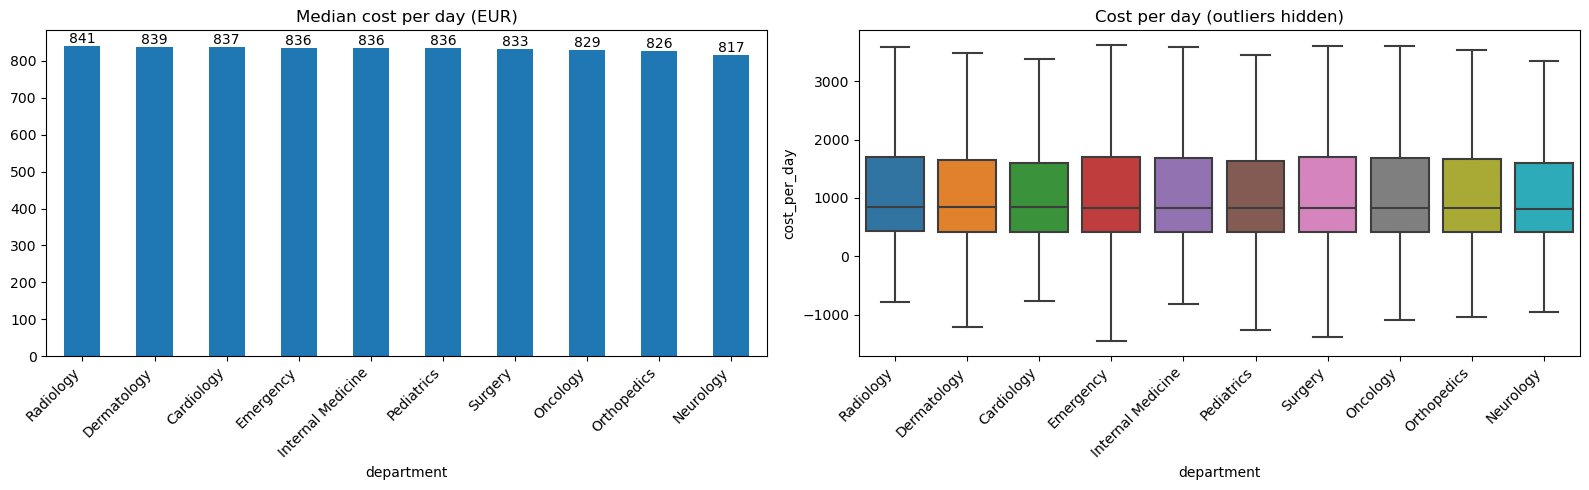

In [27]:
d = df[df.length_of_stay_days > 0].copy()            # stays of 0 days would divide by zero
d["cost_per_day"] = d.total_charges_eur / d.length_of_stay_days
med = d.groupby("department").cost_per_day.median().round(0).sort_values(ascending=False)
print(med)

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
med.plot.bar(ax=ax[0], title="Median cost per day (EUR)")
ax[0].bar_label(ax[0].containers[0], fmt="%.0f"); plt.setp(ax[0].get_xticklabels(), rotation=45, ha="right")
sns.boxplot(data=d, x="department", y="cost_per_day", order=med.index, showfliers=False, ax=ax[1])
ax[1].set_title("Cost per day (outliers hidden)"); plt.setp(ax[1].get_xticklabels(), rotation=45, ha="right")
plt.tight_layout(); plt.show()

**Conclusion**
- **What we see:** The median cost per day is about EUR 817 to EUR 841 in every department, with Radiology highest and Neurology lowest.
- **Why it happened:** Charges and length of stay were generated in the same way for all departments, so the ratio is the same everywhere and the 3% gap is noise. In real hospitals intensive care and surgery cost far more per day than radiology.

### Q19. Is a higher bill associated with a longer stay?
Do longer stays cost more?

Correlation: 0.002


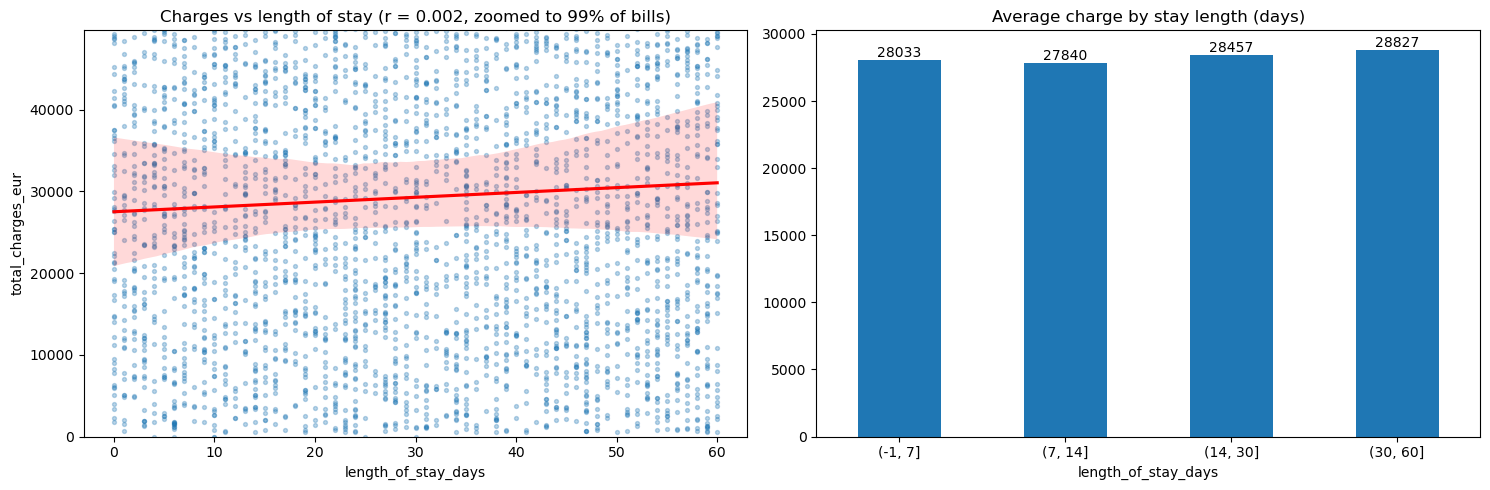

In [28]:
r = df.total_charges_eur.corr(df.length_of_stay_days)
print("Correlation:", round(r, 3))

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sample = df.sample(3000, random_state=1)
sns.regplot(data=sample, x="length_of_stay_days", y="total_charges_eur",
            scatter_kws={"alpha": 0.3, "s": 8}, line_kws={"color": "red"}, ax=ax[0])
ax[0].set_ylim(0, df.total_charges_eur.quantile(0.99))
ax[0].set_title(f"Charges vs length of stay (r = {r:.3f}, zoomed to 99% of bills)")
bins = pd.cut(df.length_of_stay_days, [-1, 7, 14, 30, 60])
df.groupby(bins, observed=True).total_charges_eur.mean().plot.bar(ax=ax[1], rot=0, title="Average charge by stay length (days)")
ax[1].bar_label(ax[1].containers[0], fmt="%.0f")
plt.tight_layout(); plt.show()

**Conclusion**
- **What we see:** The correlation between charges and length of stay is 0.002, which means no relationship. The average bill is almost the same for short and long stays.
- **Why it happened:** `total_charges_eur` was generated independently of `length_of_stay_days`. In real hospitals charges grow with the number of days (days x daily cost + procedures), so a clear upward line would appear.

## Part E: Outcomes (Q20 to Q23)

### Q20. What is the 30-day readmission rate, overall and by department and diagnosis?
Which department or diagnosis has the highest readmission rate? The green band is the typical real-world range (10-20%).

Overall: 50.0%


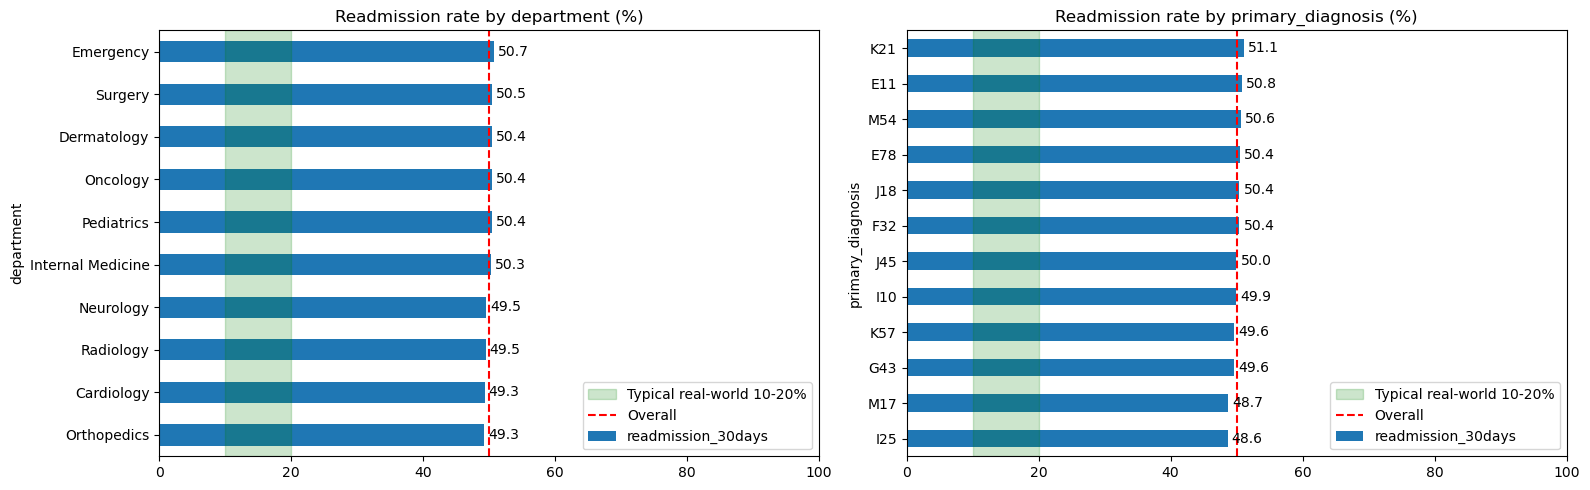

In [29]:
overall = df.readmission_30days.mean()
print(f"Overall: {overall:.1%}")

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
for a, col in zip(ax, ["department", "primary_diagnosis"]):
    r = df.groupby(col).readmission_30days.mean().sort_values() * 100
    r.plot.barh(ax=a, title=f"Readmission rate by {col} (%)")
    a.bar_label(a.containers[0], fmt="%.1f", padding=3)
    a.axvspan(10, 20, color="green", alpha=0.2, label="Typical real-world 10-20%")
    a.axvline(overall * 100, color="red", ls="--", label="Overall")
    a.set_xlim(0, 100); a.legend(loc="lower right")
plt.tight_layout(); plt.show()

**Conclusion**
- **What we see:** The overall readmission rate is 50.0%. Emergency is highest (50.7%), Cardiology and Orthopedics lowest (49.3%), and every department is within one point of 50%.
- **Why it happened:** A rate of exactly 50% that is identical in every group is the pattern of a fair coin toss, so the flag was generated randomly with no link to department or diagnosis. A real 30-day readmission rate is usually 10% to 20% and differs between groups.

### Q21. Are older patients, or patients with longer stays, more likely to be readmitted?
Does the readmission risk grow with age or length of stay?

age_group
0-17     49.8
18-35    50.7
36-50    50.2
51-65    50.3
66-80    49.2
80+      49.8
Name: readmission_30days, dtype: float64
length_of_stay_days
(-1, 7]     50.5
(7, 14]     50.0
(14, 30]    50.1
(30, 60]    49.8
Name: readmission_30days, dtype: float64


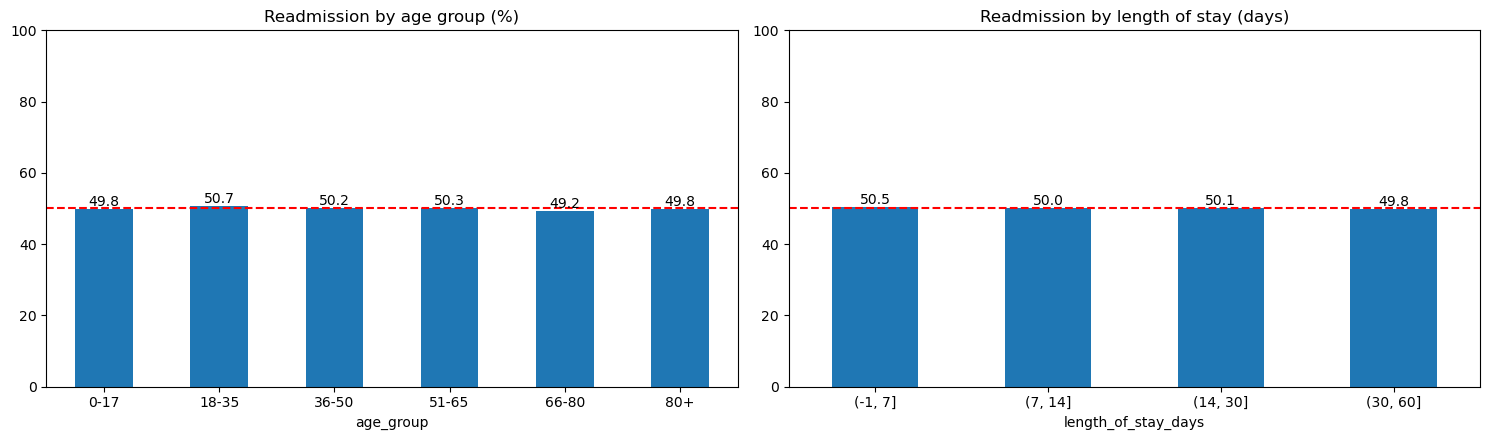

In [30]:
by_age = df.groupby("age_group", observed=True).readmission_30days.mean() * 100
by_los = df.groupby(pd.cut(df.length_of_stay_days, [-1, 7, 14, 30, 60]), observed=True).readmission_30days.mean() * 100
print(by_age.round(1)); print(by_los.round(1))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for a, s, title in zip(ax, [by_age, by_los], ["Readmission by age group (%)", "Readmission by length of stay (days)"]):
    s.plot.bar(ax=a, rot=0, title=title)
    a.bar_label(a.containers[0], fmt="%.1f"); a.set_ylim(0, 100)
    a.axhline(df.readmission_30days.mean() * 100, color="red", ls="--")
plt.tight_layout(); plt.show()

**Conclusion**
- **What we see:** Readmission is about 49% to 51% in every age group and every stay-length group.
- **Why it happened:** The readmission flag is the same random 50/50 toss for everybody, so age and length of stay cannot change it. In reality older patients and long or complicated stays have a higher readmission risk.

### Q22. Does satisfaction differ by department, discharge status or length of stay?
What do the satisfaction scores look like, and do they depend on the department or the outcome?

1    0.106
2    0.106
3    0.574
4    0.107
5    0.107
Name: satisfaction_score, dtype: float64


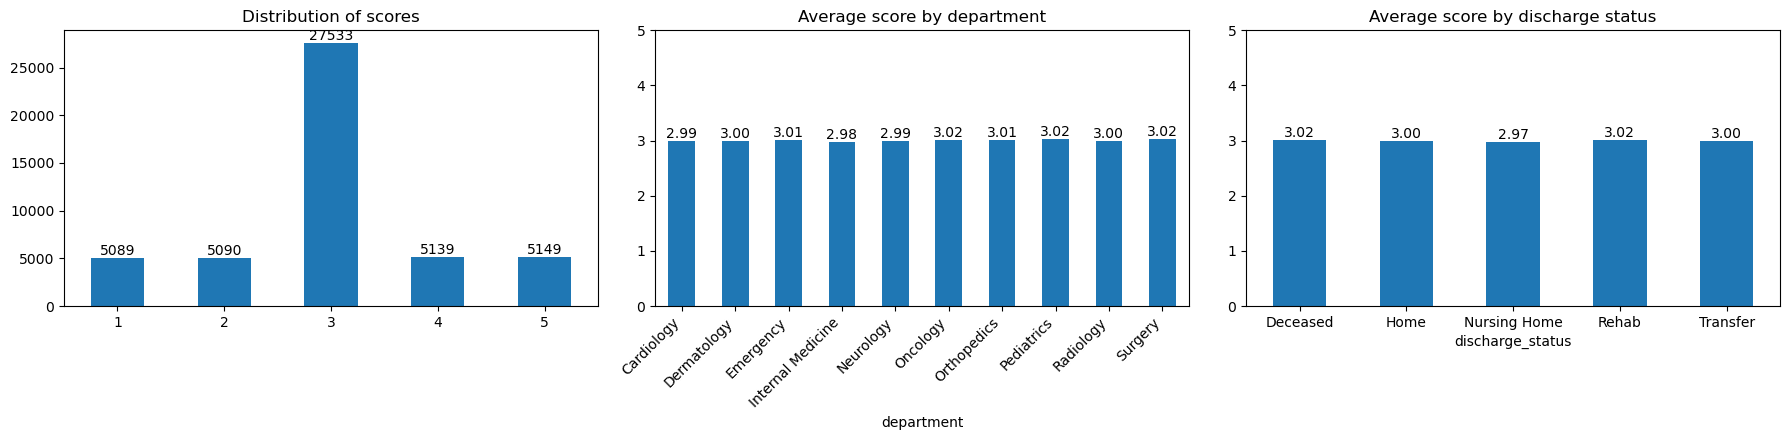

In [31]:
print(df.satisfaction_score.value_counts(normalize=True).sort_index().round(3))

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
sc = df.satisfaction_score.value_counts().sort_index()
sc.plot.bar(ax=ax[0], rot=0, title="Distribution of scores")
ax[0].bar_label(ax[0].containers[0])
df.groupby("department").satisfaction_score.mean().plot.bar(ax=ax[1], title="Average score by department")
df.groupby("discharge_status").satisfaction_score.mean().plot.bar(ax=ax[2], rot=0, title="Average score by discharge status")
for a in ax[1:]:
    a.bar_label(a.containers[0], fmt="%.2f"); a.set_ylim(0, df.satisfaction_score.max())
plt.setp(ax[1].get_xticklabels(), rotation=45, ha="right")
plt.tight_layout(); plt.show()

**Conclusion**
- **What we see:** The average satisfaction is about 3.0 for every department and every discharge status, and 57% of all scores are 3.
- **Why it happened:** The missing scores were filled with the median (3), which creates the tall bar at 3 and pulls every group average towards 3. The remaining scores are random, so they do not depend on department, outcome or stay. Even 'Deceased' patients have a score, which is another sign that the column is not real survey data.

### Q23. What is the mortality (Deceased) rate by department and age group?
Does mortality rise with age or differ by department?

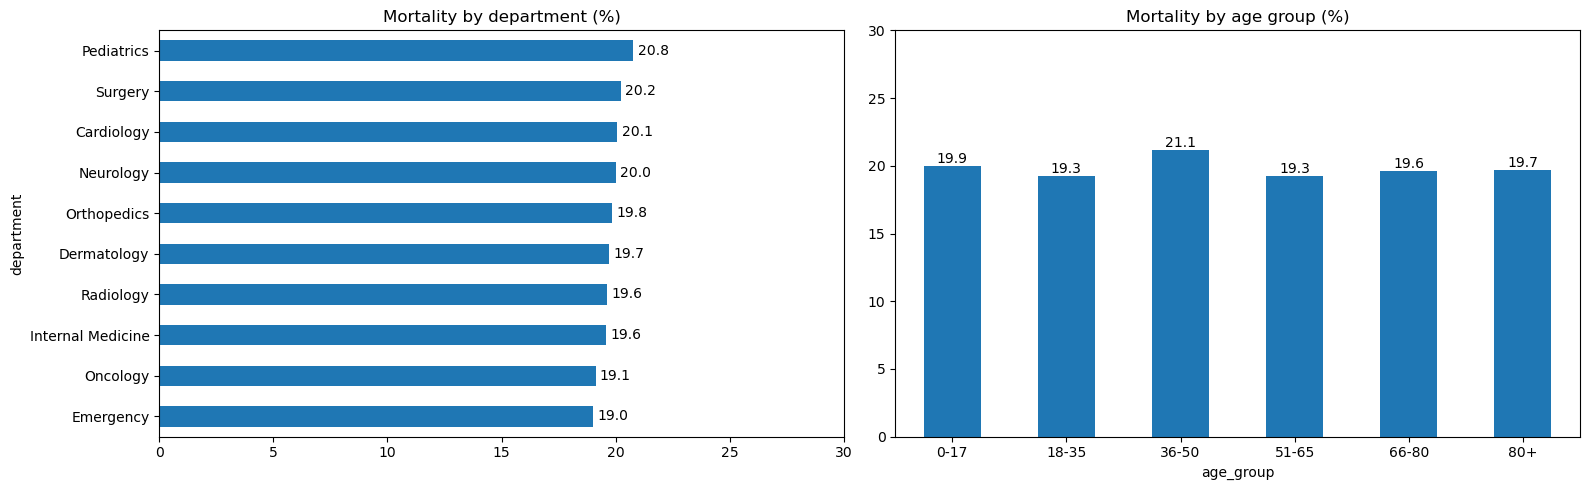

Overall mortality: 19.8%


In [32]:
df["deceased"] = df.discharge_status == "Deceased"
by_dept = df.groupby("department").deceased.mean().sort_values() * 100
by_age = df.groupby("age_group", observed=True).deceased.mean() * 100

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
by_dept.plot.barh(ax=ax[0], title="Mortality by department (%)")
ax[0].bar_label(ax[0].containers[0], fmt="%.1f", padding=3)
by_age.plot.bar(ax=ax[1], rot=0, title="Mortality by age group (%)")
ax[1].bar_label(ax[1].containers[0], fmt="%.1f")
for a in ax:
    a.set_xlim(0, 30) if a is ax[0] else a.set_ylim(0, 30)
plt.tight_layout(); plt.show()
print(f"Overall mortality: {df.deceased.mean():.1%}")

**Conclusion**
- **What we see:** Mortality is about 19% to 21% in every department and every age group, with Pediatrics highest at 20.8%. Deaths do not rise with age.
- **Why it happened:** `discharge_status` was assigned randomly, with about a 20% chance of 'Deceased' for every patient. Real hospital mortality is only a few percent, higher in elderly patients and intensive care, and close to zero in pediatrics.

## Part F: Time and relationships (Q24 to Q27)

### Q24. How many patients are admitted each year and month? Is there seasonality?
Does the number of admissions grow over the years or change with the season?

2022    11975
2023    12108
2024    12014
2025    11903
Name: adm_year, dtype: int64


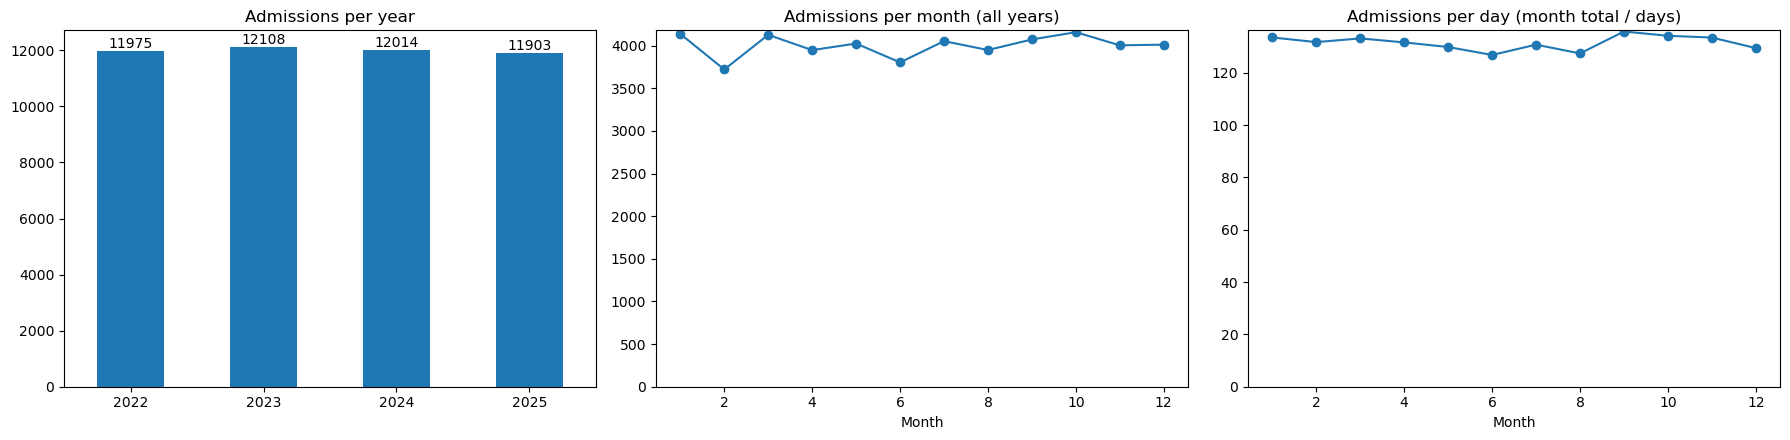

In [33]:
df["adm_year"] = df.admission_date.dt.year
df["adm_month"] = df.admission_date.dt.month
print(df.adm_year.value_counts().sort_index())

monthly = df.groupby("adm_month").size()
days_in_month = pd.Series([31, 28.25, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31], index=range(1, 13))

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
df.adm_year.value_counts().sort_index().plot.bar(ax=ax[0], rot=0, title="Admissions per year")
ax[0].bar_label(ax[0].containers[0])
monthly.plot(ax=ax[1], marker="o", title="Admissions per month (all years)")
(monthly / days_in_month).plot(ax=ax[2], marker="o", title="Admissions per day (month total / days)")
for a in ax[1:]:
    a.set_xlabel("Month"); a.set_ylim(0, None)
plt.tight_layout(); plt.show()

**Conclusion**
- **What we see:** About 12,000 admissions every year (11,903 in 2025 to 12,108 in 2023), and every month has between 3,700 and 4,200. February is the lowest (3,720).
- **Why it happened:** Admission dates were spread evenly over 2022-2025, so there is no growth, decline or seasonal peak. February is low only because it has fewer days; once the totals are divided by the number of days (right chart) the dip disappears. Real hospitals show winter peaks (flu, respiratory illness).

### Q25. Which numeric variables are correlated?
Do any numeric columns move together? (Only the lower triangle is shown.)

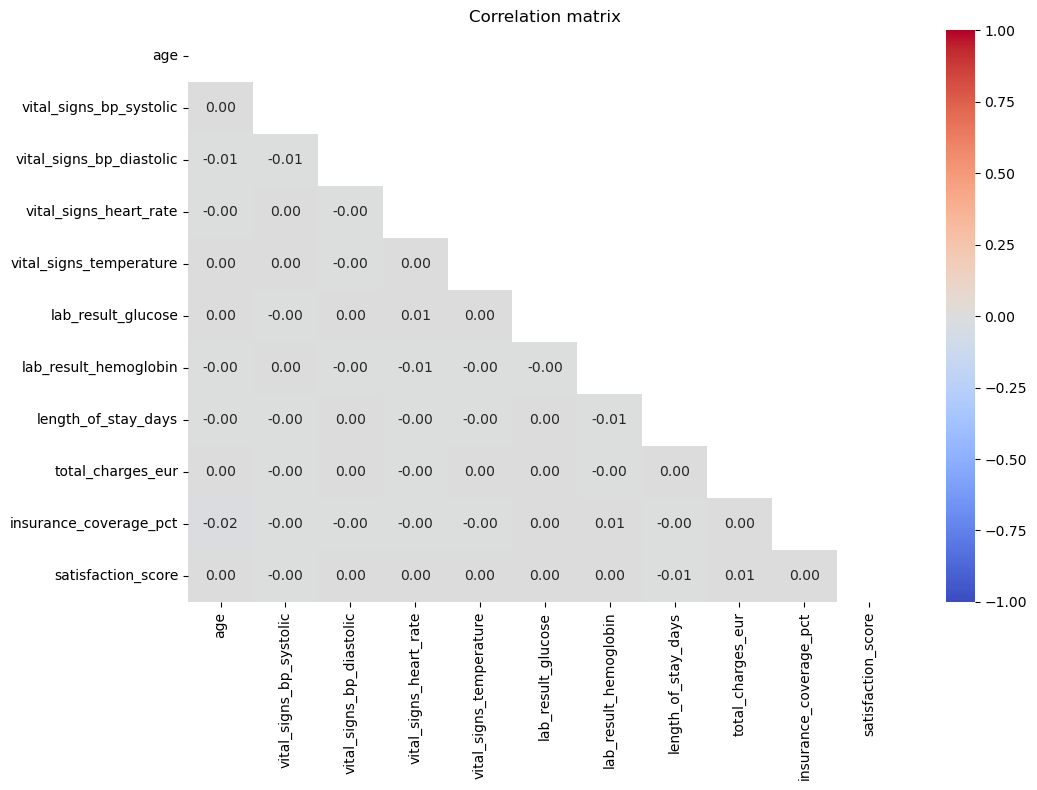

insurance_coverage_pct    age                  0.016
satisfaction_score        total_charges_eur    0.007
vital_signs_bp_diastolic  age                  0.007
dtype: float64


In [34]:
num = ["age", "vital_signs_bp_systolic", "vital_signs_bp_diastolic", "vital_signs_heart_rate",
       "vital_signs_temperature", "lab_result_glucose", "lab_result_hemoglobin",
       "length_of_stay_days", "total_charges_eur", "insurance_coverage_pct", "satisfaction_score"]
corr = df[num].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(11, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation matrix"); plt.tight_layout(); plt.show()

print(corr.where(~mask).stack().abs().sort_values(ascending=False).head(3).round(3))

**Conclusion**
- **What we see:** The heatmap is almost blank. The strongest correlation is only about 0.016 (age and insurance coverage).
- **Why it happened:** Every column was generated on its own, so no column knows about another. With 48,000 rows, pure chance gives correlations of about +/-0.01 to 0.02, so 0.016 is noise. Real data would show links such as stay and charges, or age and blood pressure.

### Q26. Create a blood-pressure category (Normal / Elevated / Stage 1 / Stage 2) and show its distribution.
How are patients spread over the blood-pressure categories?

Normal      13.0
Elevated     4.3
Stage 1     15.0
Stage 2     67.7
Name: bp_category, dtype: float64


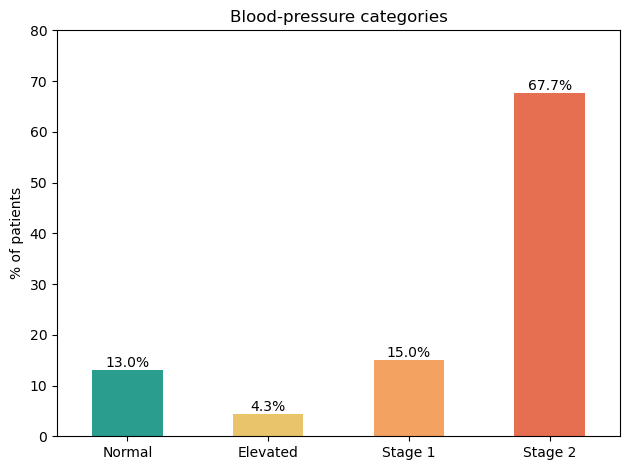

In [35]:
s, d_bp = df.vital_signs_bp_systolic, df.vital_signs_bp_diastolic
df["bp_category"] = np.select(
    [(s >= 140) | (d_bp >= 90), (s >= 130) | (d_bp >= 80), (s >= 120) & (d_bp < 80)],
    ["Stage 2", "Stage 1", "Elevated"], default="Normal")

order = ["Normal", "Elevated", "Stage 1", "Stage 2"]
share = df.bp_category.value_counts(normalize=True).reindex(order) * 100
print(share.round(1))

ax = share.plot.bar(rot=0, color=["#2a9d8f", "#e9c46a", "#f4a261", "#e76f51"])
ax.bar_label(ax.containers[0], fmt="%.1f%%"); ax.set_ylim(0, 80)
plt.title("Blood-pressure categories"); plt.ylabel("% of patients")
plt.tight_layout(); plt.show()

**Conclusion**
- **What we see:** 67.7% of patients are in Stage 2, 15% in Stage 1, 13% Normal and 4.3% Elevated.
- **Why it happened:** The rules are checked from the top, and Stage 2 needs only **one** high value (systolic >= 140 or diastolic >= 90), so most patients fall into it. 'Elevated' is tiny because it needs a narrow window (systolic 120-129 and diastolic below 80). A Stage 2 share this high is unrealistic and comes from how the blood-pressure values were generated.

### Q27. How does the average heart rate change across age groups?
Does the heart rate change with age? (The axis starts at 0 so that small differences are not exaggerated.)

age_group
0-17     84.9
18-35    85.2
36-50    85.4
51-65    84.9
66-80    85.3
80+      84.7
Name: vital_signs_heart_rate, dtype: float64


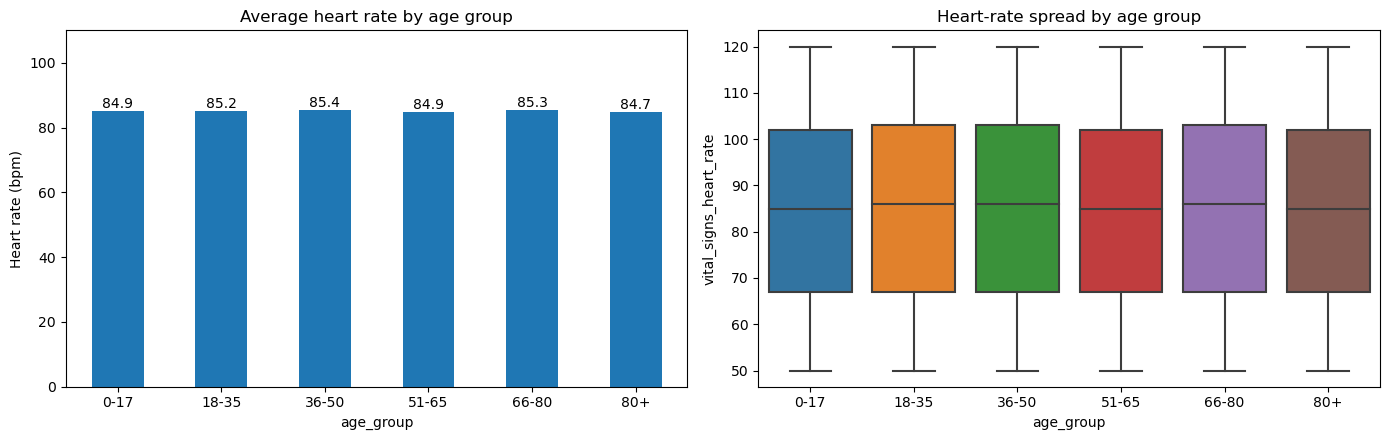

In [36]:
hr = df.groupby("age_group", observed=True).vital_signs_heart_rate.mean()
print(hr.round(1))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
hr.plot.bar(ax=ax[0], rot=0, title="Average heart rate by age group")
ax[0].bar_label(ax[0].containers[0], fmt="%.1f"); ax[0].set_ylabel("Heart rate (bpm)"); ax[0].set_ylim(0, 110)
sns.boxplot(data=df, x="age_group", y="vital_signs_heart_rate", ax=ax[1]); ax[1].set_title("Heart-rate spread by age group")
plt.tight_layout(); plt.show()

**Conclusion**
- **What we see:** The average heart rate is 84.7 to 85.4 bpm in all age groups.
- **Why it happened:** Heart rate was generated independently of age. In the earlier version the y-axis was zoomed to 80-90, which made tiny differences look big, so the axis now starts at 0. In real data children have a higher resting heart rate than adults.

## Part G: Advanced checks (Q28 to Q31)

### Q28. Which department x insurer combination has the highest total denied amount?
Where is the most money denied? The second heatmap shows the number of denied bills, to see if the amount is driven by a few huge bills.

('Orthopedics', 'Private') 8.5 million EUR
Same combination is also highest by count? False


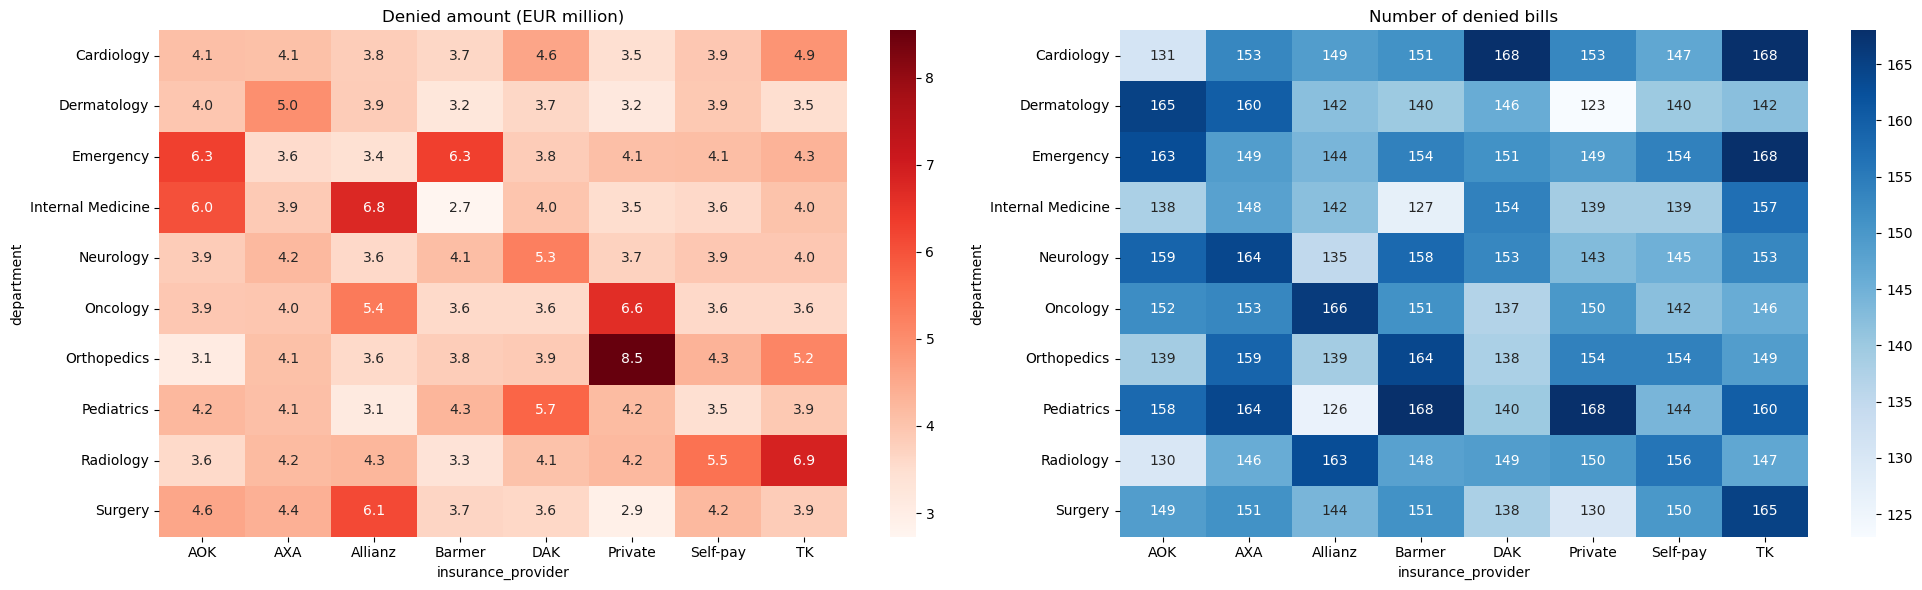

In [37]:
den = df[df.payment_status == "Denied"]
amt = den.pivot_table(index="department", columns="insurance_provider", values="total_charges_eur", aggfunc="sum") / 1e6
cnt = den.pivot_table(index="department", columns="insurance_provider", values="patient_id", aggfunc="count")
print(amt.stack().idxmax(), round(amt.stack().max(), 1), "million EUR")
print("Same combination is also highest by count?", cnt.stack().idxmax() == amt.stack().idxmax())

fig, ax = plt.subplots(1, 2, figsize=(20, 6))
sns.heatmap(amt, annot=True, fmt=".1f", cmap="Reds", ax=ax[0]); ax[0].set_title("Denied amount (EUR million)")
sns.heatmap(cnt, annot=True, fmt=".0f", cmap="Blues", ax=ax[1]); ax[1].set_title("Number of denied bills")
plt.tight_layout(); plt.show()

**Conclusion**
- **What we see:** Orthopedics with Private insurance has the highest denied amount (about EUR 8.5 million), but the other combinations are close.
- **Why it happened:** Denial was assigned randomly, so every combination has a similar number of denied bills (right heatmap). The winner is decided by which combination happened to get the few very large bills, not by a real denial problem. The result is therefore not a reliable business finding.

### Q29. Plot total monthly revenue with a 3-month rolling average.
Is revenue growing, and what causes the peaks? The dashed line shows revenue without bills above EUR 200,000.

Lowest month: Jun 2023 23.8 | Highest month: May 2025 34.7


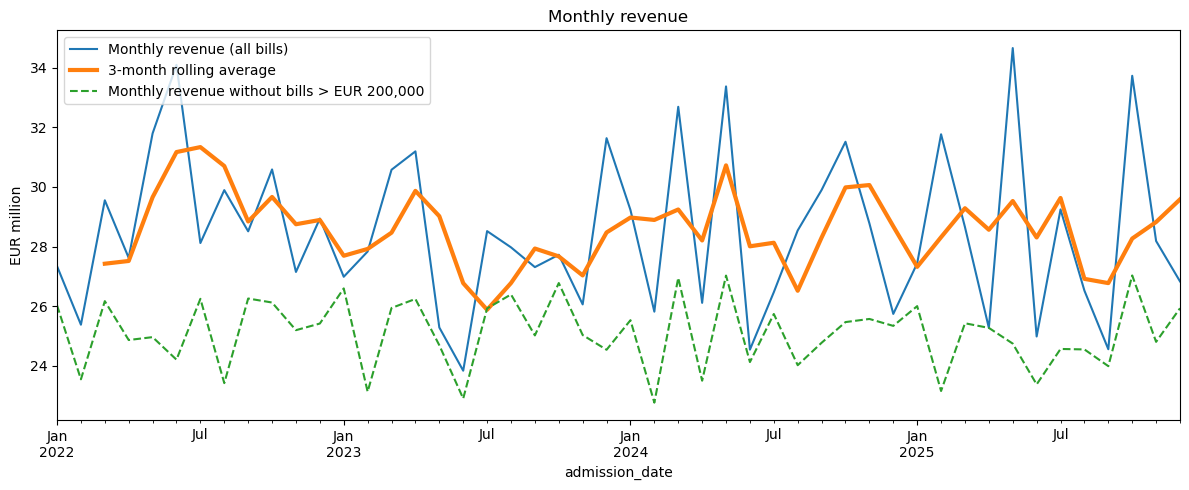

In [38]:
dated = df.dropna(subset=["admission_date"]).set_index("admission_date")
m = dated.total_charges_eur.resample("MS").sum() / 1e6
m_small = dated[dated.total_charges_eur <= 200000].total_charges_eur.resample("MS").sum() / 1e6
print("Lowest month:", m.idxmin().strftime("%b %Y"), round(m.min(), 1), "| Highest month:", m.idxmax().strftime("%b %Y"), round(m.max(), 1))

fig, ax = plt.subplots(figsize=(12, 5))
m.plot(ax=ax, label="Monthly revenue (all bills)")
m.rolling(3).mean().plot(ax=ax, lw=3, label="3-month rolling average")
m_small.plot(ax=ax, ls="--", label="Monthly revenue without bills > EUR 200,000")
ax.set_ylabel("EUR million"); ax.legend(); plt.title("Monthly revenue")
plt.tight_layout(); plt.show()

**Conclusion**
- **What we see:** Monthly revenue ranges from EUR 23.8 million (June 2023) to EUR 34.7 million (May 2025), with a typical month near EUR 28 million, and the rolling average is flat. May 2025 contains 8 bills above EUR 200,000.
- **Why it happened:** Admissions are flat (Q24) and charges do not depend on time, so there is no growth trend. The peaks come from a few extreme bills, and the dashed line (without bills above EUR 200,000) removes most of the spikes.

### Q30. At what hour of the day are records created (`created_at`)? Is the timestamp logical?
Is there a working-hours peak, and was every record created after the admission?

Records created BEFORE the admission date: 30059 (62.6%)


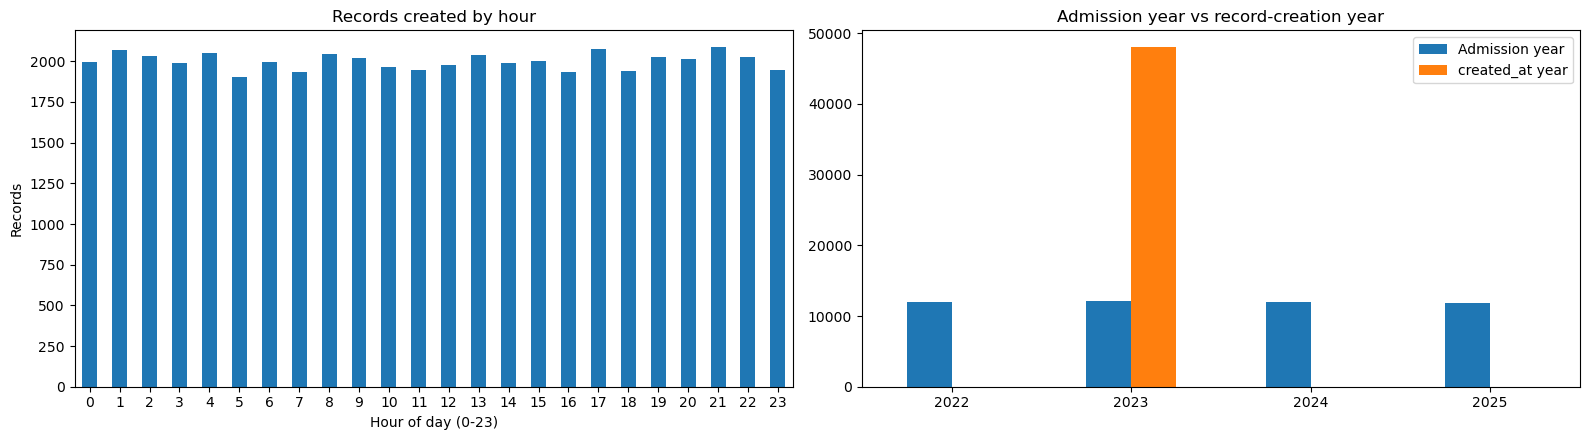

In [39]:
before = (df.created_at < df.admission_date).sum()
print(f"Records created BEFORE the admission date: {before} ({before / len(df):.1%})")

fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
df.created_at.dt.hour.value_counts().sort_index().plot.bar(ax=ax[0], rot=0, title="Records created by hour")
ax[0].set_xlabel("Hour of day (0-23)"); ax[0].set_ylabel("Records")
years = pd.DataFrame({"Admission year": df.admission_date.dt.year.value_counts().sort_index(),
                      "created_at year": df.created_at.dt.year.value_counts().sort_index()}).fillna(0)
years.plot.bar(ax=ax[1], rot=0, title="Admission year vs record-creation year")
plt.tight_layout(); plt.show()

**Conclusion**
- **What we see:** Records are created in every hour (1,906 to 2,086 per hour) with no peak, and all `created_at` dates are in 2023 even though admissions run from 2022 to 2025.
- **Why it happened:** `created_at` was generated on its own (a random time within one year) and not from `admission_date`. Records for 2024 and 2025 admissions were therefore created before the admissions happened, which is impossible. In a real system records are created at or after the admission and peak in working hours.

### Q31. Are deceased patients flagged as readmitted within 30 days?
A patient who died cannot be readmitted. How many deceased patients still have the readmission flag?

readmission_30days  False  True
discharge_status               
Deceased             4712  4793
Home                 7284  7145
Nursing Home         2379  2385
Rehab                4833  4867
Transfer             4787  4815
Deceased AND readmitted: 4793


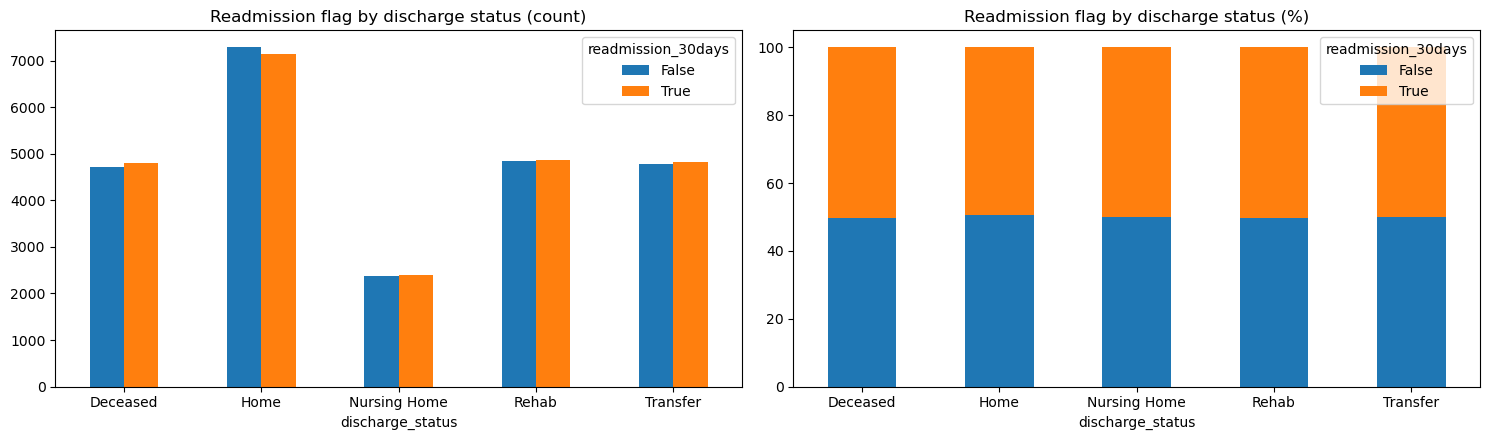

In [40]:
ct = pd.crosstab(df.discharge_status, df.readmission_30days)
print(ct)
print("Deceased AND readmitted:", ct.loc["Deceased"].iloc[-1])

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ct.plot.bar(ax=ax[0], rot=0, title="Readmission flag by discharge status (count)")
(pd.crosstab(df.discharge_status, df.readmission_30days, normalize="index") * 100).plot.bar(
    ax=ax[1], stacked=True, rot=0, title="Readmission flag by discharge status (%)")
plt.tight_layout(); plt.show()

**Conclusion**
- **What we see:** 4,793 deceased patients are marked as readmitted within 30 days, and the flag is split about 50/50 in every discharge status.
- **Why it happened:** The readmission flag was generated randomly and ignores `discharge_status`. The data has no rule such as "deceased means readmission = 0". This is a logical error that should be fixed or excluded before any real analysis.

## Final Conclusion

**What we found:** Almost every variable is spread evenly and is unrelated to every other variable.

**Why it happened (four reasons that repeat in the questions):**
1. **Equal-chance sampling.** Categories (cities, insurers, diagnoses, drugs, blood types) have almost equal counts, close to total / number of categories (Q5, Q7, Q8, Q9).
2. **Independent columns.** Each column was generated alone, so there are no links such as diabetes -> high glucose, longer stay -> higher bill, or older age -> higher mortality (Q10 to Q13, Q18 to Q21, Q23, Q25, Q27).
3. **Missing business rules.** Impossible combinations exist: adults in Pediatrics, Self-pay with coverage, deceased patients readmitted, records created before admission (Q3, Q4, Q30, Q31).
4. **Hidden missing values and cut-off effects.** 'Unknown' and 'None Prescribed' hide missing information, satisfaction scores were filled with the median, and gender gaps in anaemia come from different thresholds (Q1, Q14, Q22).

**What this means:** The dataset looks randomly generated. It is very good for practising Pandas, data cleaning and charts, but it should **not** be used for real clinical or business decisions.